# Laboratorio 7: NLP end-to-end y embeddings

CC3092 Deep Learning y Sistemas Inteligentes. Roberto Barreda, 23354.

Las figuras se guardan en `figures/`, las tablas en `results/` y los vectores del mejor modelo en `vectors/`.

In [1]:
import os, re, html, time, math, json, random, platform, subprocess, warnings
from array import array
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr

try:
    import truststore  # usa los certificados de Windows para las descargas
    truststore.inject_into_ssl()
except ImportError:
    pass

from datasets import load_dataset
from datasets.utils.logging import set_verbosity_error
from huggingface_hub.utils import logging as hf_logging
import gensim
import gensim.downloader as api
from gensim.models import Word2Vec, KeyedVectors
from gensim.models.callbacks import CallbackAny2Vec
from gensim.test.utils import datapath

warnings.filterwarnings("ignore", category=FutureWarning)
set_verbosity_error(); hf_logging.set_verbosity_error()
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for d in ["data", "figures", "results", "vectors"]:
    os.makedirs(d, exist_ok=True)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})


def nombre_cpu():
    try:
        r = subprocess.run(["powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name"],
                           capture_output=True, text=True, timeout=30)
        return r.stdout.strip() or platform.processor()
    except Exception:
        return platform.processor()


CPU = nombre_cpu()
GPU = torch.cuda.get_device_name(0) if DEV.type == "cuda" else "sin GPU"
print(f"torch {torch.__version__}, gensim {gensim.__version__}")
print(f"CPU: {CPU} ({os.cpu_count()} hilos)")
print(f"GPU: {GPU}")

torch 2.13.0+cu130, gensim 4.4.0
CPU: 13th Gen Intel(R) Core(TM) i9-13900HX (32 hilos)
GPU: NVIDIA GeForce RTX 4080 Laptop GPU


## 1. Datos

WikiText-103 (raw) para entrenar los embeddings, AG News para la clasificación y GloVe de 100 dimensiones como referencia. Los benchmarks vienen incluidos en gensim.

In [2]:
corpus = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1")
news = load_dataset("fancyzhx/ag_news")
glove = api.load("glove-wiki-gigaword-100")

analogias_path = datapath("questions-words.txt")  # 19,544 analogías, 14 categorías
wordsim_path = datapath("wordsim353.tsv")
simlex_path = datapath("simlex999.txt")

print(corpus)
print(news)
print(f"GloVe: {len(glove.key_to_index):,} palabras, {glove.vector_size} dimensiones")

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 1801350
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
GloVe: 400,000 palabras, 100 dimensiones


## 2. Exploración y preprocesamiento del texto

### 2.1 Tamaño del corpus

WikiText-103 ya viene tokenizado por espacios, así que el conteo por espacios coincide con el oficial. Un artículo empieza con una línea `" = Título = "` rodeada de líneas vacías; los subtítulos usan `" = = "`.

In [3]:
ART_RE = re.compile(r"^ = [^=].* = \n$")
texto = {s: corpus[s]["text"][:] for s in ["train", "validation", "test"]}


def es_titulo(lines, i):
    return bool(ART_RE.match(lines[i])) and lines[i - 1] == "" and (i + 1 == len(lines) or lines[i + 1] == "")


def estadisticas(lines):
    return {"artículos": sum(es_titulo(lines, i) for i in range(1, len(lines)) if lines[i].startswith(" = ")),
            "líneas": len(lines),
            "líneas no vacías": sum(1 for l in lines if l.strip()),
            "tokens": sum(len(l.split()) for l in lines)}


tabla_corpus = pd.DataFrame({s: estadisticas(texto[s]) for s in texto}).T
tabla_corpus.loc["total"] = tabla_corpus.sum()
tabla_corpus.to_csv("results/corpus_stats.csv")
tabla_corpus

,artículos,líneas,líneas no vacías,tokens
train,28472,1801350,1165029,101425671
validation,60,3760,2461,213886
test,60,4358,2891,241211
total,28592,1809468,1170381,101880768


### 2.2 Normalización y tokenizador

GloVe 6B está en minúsculas y se tokenizó con el tokenizador de Stanford, que separa clíticos ("do n't", "it 's"), mantiene palabras con guion ("well-known") y números con separadores ("1,000", "3.5"). El tokenizador propio replica esas decisiones para que una palabra tenga la misma forma en los tres vocabularios; si no, una consulta como "well-known" existiría en GloVe y no en el modelo propio.

Primero se reconstruyen los marcadores de WikiText (`" @-@ "`, `" @,@ "`, `" @.@ "`): "role @-@ playing" pasa a "role-playing" y "3 @.@ 5" a "3.5". Luego todo pasa a minúsculas, se separan los clíticos y los números quedan como tokens, porque GloVe tiene vectores para años y cifras. La puntuación se descarta: no aparece en los benchmarks y ocupa posiciones de la ventana de contexto. En AG News también se decodifican entidades HTML ("#39;", "quot;"). Los tokens especiales `<pad>` y `<unk>` solo se agregan en el clasificador; WikiText-103 raw no trae `<unk>`, así que min_count decide qué palabras quedan fuera del vocabulario.

In [4]:
MARCAS_WIKI = [(" @-@ ", "-"), (" @,@ ", ","), (" @.@ ", ".")]
NT_SEPARADO = re.compile(r"(?<=[^\W_])n 't\b")       # WikiText escribe "didn 't"
NT = re.compile(r"(?<=[^\W_])n't\b")                 # texto normal: "didn't"
CLITICO = re.compile(r"(?<=[^\W_])'(s|re|ve|ll|d|m)\b")
TOKEN_RE = re.compile(
    r"(?:[^\W\d_]\.){2,}"            # siglas: u.s., p.m., e.g.
    r"|\d+(?:[.,]\d+)+"              # números con separadores: 3.5, 1,000
    r"|n't|'(?:s|re|ve|ll|d|m)\b"    # clíticos como en GloVe
    r"|[^\W_]+(?:[-'][^\W_]+)*"      # palabras, compuestos con guion y números
)


def normalizar(texto):
    for a, b in MARCAS_WIKI:
        texto = texto.replace(a, b)
    texto = html.unescape(texto.replace("#39;", "'").replace("quot;", '"').replace("\\", " "))
    texto = texto.lower().replace("\u2019", "'")
    texto = NT_SEPARADO.sub(" n't", texto)
    texto = NT.sub(" n't", texto)
    return CLITICO.sub(r" '\1", texto)


def tokenizar(texto):
    """Texto crudo a lista de tokens; la puntuación suelta se descarta."""
    return TOKEN_RE.findall(normalizar(texto))


print(tokenizar(texto["train"][3][:300]))

['senjō', 'no', 'valkyria', '3', 'unrecorded', 'chronicles', 'japanese', '戦場のヴァルキュリア3', 'lit', 'valkyria', 'of', 'the', 'battlefield', '3', 'commonly', 'referred', 'to', 'as', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', 'is', 'a', 'tactical', 'role-playing', 'video', 'game', 'developed', 'by', 'sega', 'and', 'media', 'vision', 'for', 'the', 'playstation', 'portable', 'released', 'in', 'janu']


### 2.3 Comparación con NLTK

Se compara con `nltk.word_tokenize` (Treebank) en 10 oraciones; la salida de NLTK se pasa a minúsculas para que solo cuenten las diferencias de segmentación.

In [5]:
import nltk
from nltk.tokenize import word_tokenize
nltk.download("punkt_tab", quiet=True)

oraciones = [
    "Don't worry, I'm sure they'll arrive at 5 p.m. tomorrow.",
    "The U.S. economy grew 3.5% in 2011, according to Dr. Smith.",
    "She's a well-known co-founder of the start-up.",
    "We can't and won't accept the $1,000,000 offer.",
    "Mr. O'Neill bought rock 'n' roll records in the 1990s.",
    "The students' grades (e.g., A+, B-) were posted online.",
    "I'm gonna visit New York City... maybe.",
    "E-mail me at john.doe@example.com before Jan. 5th.",
    "The 21st-century state-of-the-art system costs 2.5 million pounds.",
    '"It\'s over," he said; "we lost 2-1."',
]
filas = []
for s in oraciones:
    a, b = tokenizar(s), [t.lower() for t in word_tokenize(s)]
    filas.append({"oración": s, "propio": " ".join(a), "NLTK": " ".join(b),
                  "solo propio": " ".join(t for t in a if t not in b),
                  "solo NLTK": " ".join(t for t in b if t not in a)})
tabla_tok = pd.DataFrame(filas)
tabla_tok.to_csv("results/tokenizador_vs_nltk.csv", index=False)
tabla_tok[["oración", "solo propio", "solo NLTK"]]

,oración,solo propio,solo NLTK
0,"Don't worry, I'm sure they'll arrive at 5 p.m. tomorrow.",,", ."
1,"The U.S. economy grew 3.5% in 2011, according to Dr. Smith.",dr,"% , dr. ."
2,She's a well-known co-founder of the start-up.,,.
3,"We can't and won't accept the $1,000,000 offer.",,$ .
4,Mr. O'Neill bought rock 'n' roll records in the 1990s.,mr n,mr. 'n ' .
5,"The students' grades (e.g., A+, B-) were posted online.",a b,"' ( , a+ , b- ) ."
6,I'm gonna visit New York City... maybe.,gonna,gon na ... .
7,E-mail me at john.doe@example.com before Jan. 5th.,john doe example com jan,john.doe @ example.com jan. .
8,The 21st-century state-of-the-art system costs 2.5 million pounds.,,.
9,"""It's over,"" he said; ""we lost 2-1.""",,"`` , '' ; `` . ''"


Ambos separan los clíticos igual ("do n't", "ca n't", "'s") y dejan intactos los compuestos con guion ("well-known", "state-of-the-art") y los números ("1,000,000", "3.5"). Difieren en la puntuación, que NLTK conserva como token; en abreviaturas con un solo punto ("Mr.", "Dr.", "Jan."), donde NLTK mantiene el punto y el propio lo quita; en "gonna", que NLTK parte en "gon na"; en el correo, que NLTK deja como "john.doe @ example.com"; y en "rock 'n' roll".

### 2.4 Frecuencia contra rango (ley de Zipf)

Se tokeniza todo el split de entrenamiento y cada token se guarda como un entero. Guardar 85 millones de strings de Python no cabe en 16 GB de RAM, así que el vocabulario se construye sobre la marcha y el resultado queda en caché en `data/`.

In [6]:
CACHE_IDS = "data/wikitext103_train_ids.npz"
if os.path.exists(CACHE_IDS):
    z = np.load(CACHE_IDS, allow_pickle=True)
    ids_full, sent_len_full, sent_doc_full, i2w_full = z["ids"], z["sent_len"], z["sent_doc"], list(z["i2w"])
else:
    t0 = time.time()
    w2i_tmp, ids, sent_len, sent_doc, doc = {}, array("i"), array("i"), array("i"), -1
    lineas = texto["train"]
    for i, l in enumerate(lineas):
        if not l.strip():
            continue
        if l.startswith(" = ") and es_titulo(lineas, i):
            doc += 1
        toks = tokenizar(l)
        if toks:  # cada línea (párrafo) es una oración para skip-gram
            ids.extend([w2i_tmp.setdefault(w, len(w2i_tmp)) for w in toks])
            sent_len.append(len(toks)); sent_doc.append(doc)
    ids_full = np.frombuffer(ids, dtype=np.int32)
    sent_len_full = np.frombuffer(sent_len, dtype=np.int32)
    sent_doc_full = np.frombuffer(sent_doc, dtype=np.int32)
    i2w_full = sorted(w2i_tmp, key=w2i_tmp.get)
    np.savez(CACHE_IDS, ids=ids_full, sent_len=sent_len_full, sent_doc=sent_doc_full,
             i2w=np.array(i2w_full, dtype=object))
    del w2i_tmp, ids
    print(f"tokenizado en {time.time() - t0:.0f} s")

cnt_full = np.bincount(ids_full)
print(f"tokens: {len(ids_full):,} | tipos: {len(i2w_full):,} | oraciones: {len(sent_len_full):,} | artículos: {sent_doc_full[-1] + 1:,}")

tokenizado en 79 s


tokens: 85,311,807 | tipos: 717,893 | oraciones: 1,164,902 | artículos: 28,472


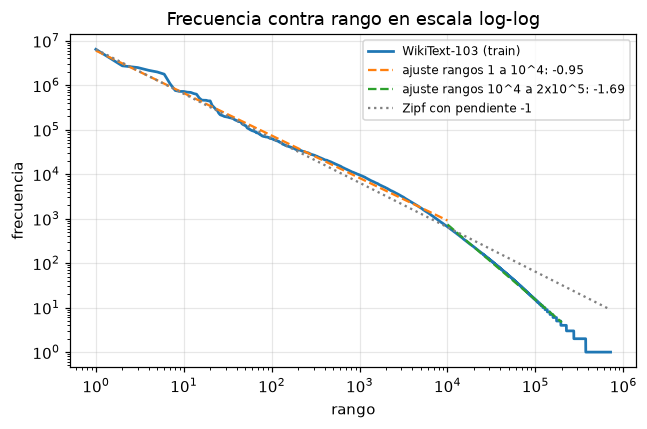

pendiente en rangos 1 a 10^4: -0.955 | en rangos 10^4 a 2x10^5: -1.692
las 10 palabras más frecuentes cubren 24.5 % de los tokens
las 1,000 palabras más frecuentes cubren 63.9 % de los tokens
las 30,000 palabras más frecuentes cubren 94.6 % de los tokens
palabras con frecuencia 1: 344,129 (47.9 % del vocabulario)


In [7]:
freq = np.sort(cnt_full)[::-1]
rango = np.arange(1, len(freq) + 1)
cobertura = {k: 100 * freq[:k].sum() / freq.sum() for k in [10, 1_000, 30_000]}


def pendiente(r0, r1):
    # rangos espaciados en escala log para que la cola no domine el ajuste
    r = np.unique(np.logspace(np.log10(r0), np.log10(r1), 200).astype(int))
    return np.polyfit(np.log10(r), np.log10(freq[r - 1]), 1)


p1, b1 = pendiente(1, 10_000)
p2, b2 = pendiente(10_000, 200_000)
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(rango, freq, lw=1.8, label="WikiText-103 (train)")
r = np.array([1, 10_000]); ax.loglog(r, 10 ** (b1 + p1 * np.log10(r)), "--", label=f"ajuste rangos 1 a 10^4: {p1:.2f}")
r = np.array([10_000, 200_000]); ax.loglog(r, 10 ** (b2 + p2 * np.log10(r)), "--", label=f"ajuste rangos 10^4 a 2x10^5: {p2:.2f}")
ax.loglog(rango, freq[0] / rango, ":", color="gray", label="Zipf con pendiente -1")
ax.set_xlabel("rango"); ax.set_ylabel("frecuencia"); ax.legend(fontsize=8)
ax.set_title("Frecuencia contra rango en escala log-log")
fig.tight_layout(); fig.savefig("figures/zipf.png", dpi=200); plt.show()

print(f"pendiente en rangos 1 a 10^4: {p1:.3f} | en rangos 10^4 a 2x10^5: {p2:.3f}")
for k, v in cobertura.items():
    print(f"las {k:,} palabras más frecuentes cubren {v:.1f} % de los tokens")
print(f"palabras con frecuencia 1: {(cnt_full == 1).sum():,} ({100 * (cnt_full == 1).mean():.1f} % del vocabulario)")

La ley de Zipf se cumple en el tramo central: entre los rangos 1 y 10^4 la pendiente es -0.96, cerca de -1. Después de 10^4 la curva cae más rápido (-1.69) porque el corpus es finito y casi la mitad del vocabulario aparece una sola vez. Las 10 palabras más frecuentes cubren 24.5 % de los tokens, las 1,000 más frecuentes 63.9 % y las 30,000 más frecuentes 94.6 %.

### 2.5 Subconjunto de entrenamiento y min_count

Los embeddings se entrenan con los primeros artículos completos de WikiText-103 hasta llegar a 50 millones de tokens. El mismo subconjunto se usa para SGNS y para gensim. El vocabulario se mide sobre ese subconjunto con distintos umbrales de frecuencia mínima.

In [8]:
N_TOKENS_OBJETIVO = 50_000_000
cum_full = np.cumsum(sent_len_full)


def prefijo(n_tokens):
    """Número de oraciones y tokens de los primeros artículos completos que suman n_tokens."""
    n_sent = int(np.searchsorted(cum_full, n_tokens)) + 1
    n_sent = int(np.searchsorted(sent_doc_full, sent_doc_full[n_sent - 1], side="right"))
    return n_sent, int(cum_full[n_sent - 1])


N_SENT, N_TOK = prefijo(N_TOKENS_OBJETIVO)
cnt_sub = np.bincount(ids_full[:N_TOK], minlength=len(i2w_full))
print(f"subconjunto: {sent_doc_full[N_SENT - 1] + 1:,} artículos, {N_SENT:,} oraciones, {N_TOK:,} tokens")

filas = []
for mc in [1, 2, 5, 10, 20, 50]:
    m = cnt_sub >= mc
    filas.append({"min_count": mc, "vocabulario": int(m.sum()),
                  "% tokens desconocidos": 100 * cnt_sub[(cnt_sub > 0) & ~m].sum() / N_TOK})
tabla_mc = pd.DataFrame(filas)
tabla_mc.to_csv("results/vocab_min_count.csv", index=False)
tabla_mc.round(3)

subconjunto: 16,822 artículos, 683,370 oraciones, 50,000,520 tokens


,min_count,vocabulario,% tokens desconocidos
0,1,527291,0.000
1,2,275515,0.504
2,5,144751,1.187
3,10,95792,1.827
4,20,64582,2.677
5,50,37696,4.351


Subir min_count reduce el vocabulario más rápido de lo que aumentan los desconocidos, por la cola larga de Zipf: min_count=5 pasa de 527,291 a 144,751 palabras y deja fuera 1.19 % de los tokens. Es el valor por defecto de gensim y el de la configuración base.

### 2.6 Submuestreo de palabras frecuentes

Se usa la fórmula de la implementación en C de word2vec, la misma de gensim, para que ambos modelos descarten las mismas proporciones. Con f(w) la frecuencia relativa y t el umbral `sample`, la probabilidad de conservar una aparición es p(w) = (sqrt(f(w) / t) + 1) t / f(w), recortada a 1. El artículo original propone descartar con probabilidad 1 - sqrt(t / f(w)); ambas penalizan más a las palabras más frecuentes.

In [9]:
def prob_conservar(counts, sample):
    """Probabilidad de conservar cada palabra (word2vec C y gensim)."""
    umbral = sample * counts.sum()
    return np.minimum((np.sqrt(counts / umbral) + 1) * umbral / counts, 1.0)


_corpus_cache = {}


def construir_corpus(frac=1.0, min_count=5):
    """Prefijo del subconjunto con vocabulario por min_count; los tokens fuera de vocabulario se eliminan, como en gensim."""
    clave = (frac, min_count)
    if clave in _corpus_cache:
        return _corpus_cache[clave]
    n_sent, n_tok = (N_SENT, N_TOK) if frac == 1.0 else prefijo(int(frac * N_TOK))
    ids = ids_full[:n_tok]
    cnt = np.bincount(ids, minlength=len(i2w_full))
    keep = np.where(cnt >= min_count)[0]
    keep = keep[np.argsort(-cnt[keep], kind="stable")]  # orden por frecuencia, igual que gensim
    remap = np.full(len(i2w_full), -1, np.int32)
    remap[keep] = np.arange(len(keep), dtype=np.int32)
    tok = remap[ids]
    sid = np.repeat(np.arange(n_sent, dtype=np.int32), sent_len_full[:n_sent])
    m = tok >= 0
    c = {"frac": frac, "min_count": min_count, "n_sent": n_sent, "n_tokens": n_tok,
         "words": [i2w_full[i] for i in keep], "counts": cnt[keep], "tok": tok[m], "sid": sid[m]}
    c["w2i"] = {w: i for i, w in enumerate(c["words"])}
    _corpus_cache[clave] = c
    return c


base = construir_corpus(1.0, 5)
filas = []
for sample in [1e-3, 1e-4, 1e-5]:
    p = prob_conservar(base["counts"], sample)
    fila = {"sample": f"{sample:.0e}"}
    for w in ["the", "of", "and"]:
        fila[f"% descartado '{w}'"] = 100 * (1 - p[base["w2i"][w]])
    fila["% descartado total"] = 100 * (1 - (p * base["counts"]).sum() / base["counts"].sum())
    filas.append(fila)
tabla_sub = pd.DataFrame(filas)
tabla_sub.to_csv("results/submuestreo.csv", index=False)
tabla_sub.round(1)

,sample,% descartado 'the',% descartado 'of',% descartado 'and',% descartado total
0,1e-03,87.2,79.4,78.3,22.4
1,1e-04,96.2,94.1,93.9,39.6
2,1e-05,98.8,98.2,98.1,63.9


Con sample=1e-4 se descarta 96.2 % de las apariciones de "the", 94.1 % de "of" y 93.9 % de "and", y 39.6 % de todos los tokens. Estas palabras aparecen junto a casi cualquier otra, así que sus pares (palabra, "the") no aportan información sobre el significado y consumen buena parte de cada epoch. Al descartarlas, el entrenamiento se concentra en palabras con contenido y la ventana efectiva alcanza palabras más lejanas, porque los huecos que dejan acercan a los vecinos reales.

### 2.7 Pares (centro, contexto) para skip-gram

Los pares se generan en GPU. Cada línea de WikiText es una oración y el contexto no cruza de una línea a otra. Con ventana fija de 5 cada palabra produce hasta 10 pares; con ventana dinámica (word2vec y gensim) el radio se sortea entre 1 y 5 para cada centro, lo que da más peso a los vecinos cercanos.

In [10]:
def generar_pares(tok_t, sid_t, ventana, keep_p=None, dinamica=True, gen=None, solo_contar=False):
    """Pares (centro, contexto) de un epoch; aplica submuestreo si keep_p no es None."""
    if keep_p is not None:
        m = torch.rand(tok_t.shape[0], device=tok_t.device, generator=gen) < keep_p[tok_t]
        tok_t, sid_t = tok_t[m], sid_t[m]
    n = tok_t.shape[0]
    if dinamica:
        radio = torch.randint(1, ventana + 1, (n,), device=tok_t.device, generator=gen, dtype=torch.int32)
    else:
        radio = torch.full((n,), ventana, device=tok_t.device, dtype=torch.int32)

    def mascaras(o):
        misma = sid_t[:-o] == sid_t[o:]
        return misma & (radio[:-o] >= o), misma & (radio[o:] >= o)  # (centro i, contexto i+o), (centro i+o, contexto i)

    conteos = [int(m.sum()) for o in range(1, ventana + 1) for m in mascaras(o)]
    if solo_contar:
        return sum(conteos)
    centros = torch.empty(sum(conteos), dtype=tok_t.dtype, device=tok_t.device)
    contextos = torch.empty_like(centros)
    k = 0
    for o in range(1, ventana + 1):  # se llena en el lugar para no duplicar la memoria con torch.cat
        m1, m2 = mascaras(o)
        for idx, c_off, x_off in [(m1.nonzero().squeeze(1), 0, o), (m2.nonzero().squeeze(1), o, 0)]:
            centros[k:k + len(idx)] = tok_t[idx + c_off]
            contextos[k:k + len(idx)] = tok_t[idx + x_off]
            k += len(idx)
    return centros, contextos


gen = torch.Generator(device=DEV); gen.manual_seed(SEED)
tok_t, sid_t = torch.tensor(base["tok"], device=DEV), torch.tensor(base["sid"], device=DEV)
keep_p = torch.tensor(prob_conservar(base["counts"], 1e-4), device=DEV, dtype=torch.float32)
tabla_pares = pd.DataFrame({
    "ventana fija 5": [generar_pares(tok_t, sid_t, 5, None, False, gen, True),
                       generar_pares(tok_t, sid_t, 5, keep_p, False, gen, True)],
    "ventana dinámica 5": [generar_pares(tok_t, sid_t, 5, None, True, gen, True),
                           generar_pares(tok_t, sid_t, 5, keep_p, True, gen, True)]},
    index=["sin submuestreo", "con submuestreo (1e-4)"])
tabla_pares.to_csv("results/pares_skipgram.csv")
print(f"tokens en vocabulario (min_count=5): {len(base['tok']):,}")
del tok_t, sid_t, keep_p
torch.cuda.empty_cache()
tabla_pares

tokens en vocabulario (min_count=5): 49,407,024


,ventana fija 5,ventana dinámica 5
sin submuestreo,476021510,287798806
con submuestreo (1e-4),280780212,170584122


Con la ventana dinámica de 5 que usan SGNS y gensim, el corpus produce 287.8 millones de pares por epoch antes del submuestreo y 170.6 millones después, 41 % menos.

## 3. Investigación: embeddings en PyTorch y gensim

**nn.Embedding(num_embeddings, embedding_dim, padding_idx, sparse).** Es una tabla de num_embeddings filas por embedding_dim columnas que recibe índices enteros y devuelve las filas correspondientes. Equivale a multiplicar un vector one-hot por la matriz sin construir el one-hot. padding_idx marca una fila, por ejemplo `<pad>`, que empieza en ceros y no recibe gradiente. Con sparse=True el gradiente es un tensor disperso que solo contiene las filas usadas en el batch; con vocabularios de cientos de miles de palabras evita escribir la tabla completa en cada paso, pero exige optimizadores que acepten gradientes dispersos (SGD, SparseAdam, Adagrad).

**nn.Embedding.from_pretrained(embeddings, freeze).** Crea la capa a partir de una matriz ya entrenada. Con freeze=True (valor por defecto) los pesos quedan fijos; con freeze=False se ajustan con la tarea.

**nn.EmbeddingBag(num_embeddings, embedding_dim, mode, padding_idx).** Busca los vectores de una bolsa de índices y los reduce en una sola operación, sin guardar la matriz intermedia de vectores por token. La entrada puede ser un tensor 2D con bolsas del mismo largo o un tensor 1D con todas las secuencias concatenadas más `offsets`, que indica dónde empieza cada bolsa; así no hace falta rellenar con `<pad>`. mode="mean" promedia los vectores, "sum" los suma y "max" toma el máximo por dimensión. Con "sum" se puede pasar per_sample_weights para ponderar cada token, por ejemplo con TF-IDF.

**CBOW y skip-gram.** CBOW predice la palabra central a partir del promedio de los vectores del contexto; skip-gram predice cada palabra del contexto a partir de la central. CBOW hace una predicción por posición y entrena más rápido; skip-gram genera un par por cada vecino, así que las palabras raras reciben más actualizaciones y quedan mejor representadas.

**Las matrices W y W'.** W guarda el vector de cada palabra cuando actúa como centro y W' cuando actúa como contexto o negativo. Con una sola matriz, el modelo tendría que dar un producto alto a una palabra consigo misma, aunque casi nunca aparece en su propio contexto. Al terminar se conserva W, que es la que gensim expone en `model.wv`; algunas variantes suman o promedian W y W'.

**Word2Vec y GloVe.** Word2Vec es predictivo: recorre el corpus con una ventana y ajusta los vectores con SGD para distinguir contextos reales de negativos muestreados. GloVe primero cuenta la matriz global de co-ocurrencia X y luego ajusta el producto punto entre w_i y w_j, más los sesgos b_i y b_j, a log X_ij con mínimos cuadrados ponderados, sin volver a leer el corpus. Levy y Goldberg (2014) mostraron que SGNS factoriza de forma implícita la matriz PMI desplazada por log k, así que ambos aprenden de las mismas estadísticas de co-ocurrencia y difieren en cómo las recorren y las ponderan.

In [11]:
torch.manual_seed(0)
emb = nn.Embedding(num_embeddings=6, embedding_dim=3, padding_idx=0)
x = torch.tensor([[1, 2, 0], [3, 0, 0]])           # dos secuencias rellenas con <pad> = 0
print("nn.Embedding:", tuple(emb(x).shape), "| fila de <pad>:", emb.weight[0].tolist())

pre = torch.randn(6, 3)
congelada = nn.Embedding.from_pretrained(pre, freeze=True)
ajustable = nn.Embedding.from_pretrained(pre, freeze=False)
print("from_pretrained requires_grad:", congelada.weight.requires_grad, ajustable.weight.requires_grad)

# EmbeddingBag con entrada 1D y offsets: bolsas [1, 2, 4] y [3, 5]
tokens = torch.tensor([1, 2, 4, 3, 5])
offsets = torch.tensor([0, 3])
for modo in ["mean", "sum", "max"]:
    bag = nn.EmbeddingBag.from_pretrained(pre, mode=modo)
    manual = {"mean": pre[[1, 2, 4]].mean(0), "sum": pre[[1, 2, 4]].sum(0), "max": pre[[1, 2, 4]].max(0).values}[modo]
    print(f"EmbeddingBag {modo:>4}: salida {tuple(bag(tokens, offsets).shape)}, coincide con el cálculo manual: {torch.allclose(bag(tokens, offsets)[0], manual)}")

nn.Embedding: (2, 3, 3) | fila de <pad>: [0.0, 0.0, 0.0]
from_pretrained requires_grad: False True
EmbeddingBag mean: salida (2, 3), coincide con el cálculo manual: True
EmbeddingBag  sum: salida (2, 3), coincide con el cálculo manual: True
EmbeddingBag  max: salida (2, 3), coincide con el cálculo manual: True


## 4. Construcción y entrenamiento de los embeddings

### 4.1 Evaluación

Para que todos los modelos respondan las mismas preguntas se fija un vocabulario de evaluación: las 30,000 palabras más frecuentes del subconjunto que también existen en GloVe y en el vocabulario de todas las iteraciones. Las analogías se evalúan con 3CosAdd sobre vectores normalizados, buscando solo dentro de ese vocabulario y excluyendo a, b y c, igual que `evaluate_word_analogies` de gensim con `restrict_vocab`. WordSim-353 se mide con la correlación de Spearman entre la similitud coseno y el puntaje humano. Durante la selección solo se usan WordSim-353 y las analogías; SimLex-999 queda para la sección 6.

In [12]:
def cargar_analogias(path=analogias_path):
    preguntas, secciones, sec = [], [], None
    for l in open(path, encoding="utf-8"):
        if l.startswith(":"):
            sec = l[1:].strip()
            continue
        preguntas.append(tuple(l.lower().split())); secciones.append(sec)
    return preguntas, secciones


def cargar_pares(path):
    return [(a.lower(), b.lower(), float(s)) for a, b, s in
            (l.rstrip("\n").split("\t") for l in open(path, encoding="utf-8") if not l.startswith("#"))]


PREGUNTAS, SECCIONES = cargar_analogias()
CATEGORIAS = list(dict.fromkeys(SECCIONES))
SEMANTICAS = set(CATEGORIAS[:5])  # las 5 primeras son semánticas, gram1 a gram9 son sintácticas
WS353, SIMLEX = cargar_pares(wordsim_path), cargar_pares(simlex_path)
CONTROL = ["king", "france", "computer", "good", "january", "run"]


class VocabEval:
    """Vocabulario de evaluación y preguntas cuyas 4 palabras están en él."""
    def __init__(self, words):
        self.words, self.pos = words, {w: i for i, w in enumerate(words)}
        filas, secs = [], []
        for q, s in zip(PREGUNTAS, SECCIONES):
            if all(w in self.pos for w in q):
                filas.append([self.pos[w] for w in q]); secs.append(s)
        self.q = torch.tensor(filas, device=DEV)
        self.sec = np.array(secs)
        self.es_sem = torch.tensor([s in SEMANTICAS for s in secs], device=DEV)

    def matriz(self, E, w2i):
        return E[torch.tensor([w2i[w] for w in self.words], device=E.device)]


@torch.no_grad()
def predecir(E, q, metodo="add", bloque=2048):
    """Índice predicho para cada pregunta (a, b, c): b - a + c con 3CosAdd o 3CosMul."""
    En = F.normalize(E.float(), dim=1)
    out = []
    for i in range(0, len(q), bloque):
        qq = q[i:i + bloque]
        a, b, c = En[qq[:, 0]], En[qq[:, 1]], En[qq[:, 2]]
        if metodo == "add":
            s = (b - a + c) @ En.T
        else:  # 3CosMul (Levy y Goldberg, 2014) con cosenos llevados a [0, 1]
            sa, sb, sc = [(x @ En.T + 1) / 2 for x in (a, b, c)]
            s = sb * sc / (sa + 1e-6)
        s.scatter_(1, qq[:, :3], -float("inf"))  # excluye a, b y c
        out.append(s.argmax(1))
    return torch.cat(out)


def evaluar_analogias(E_eval, ve, metodo="add"):
    ok = predecir(E_eval, ve.q, metodo) == ve.q[:, 3]
    return {"sem": ok[ve.es_sem].float().mean().item(), "sin": ok[~ve.es_sem].float().mean().item(),
            "total": ok.float().mean().item()}, ok.cpu().numpy()


@torch.no_grad()
def spearman(E, w2i, pares):
    validos = [(w2i[a], w2i[b], s) for a, b, s in pares if a in w2i and b in w2i]
    ia, ib, s = map(list, zip(*validos))
    En = F.normalize(E.float(), dim=1)
    cos = (En[ia] * En[ib]).sum(1).cpu().numpy()
    return spearmanr(cos, s).correlation, len(validos)


@torch.no_grad()
def vecinos(E, words, w2i, consultas=CONTROL, k=5):
    En = F.normalize(E.float(), dim=1)
    res = {}
    for w in consultas:
        s = En @ En[w2i[w]]
        s[w2i[w]] = -float("inf")
        res[w] = [words[i] for i in s.topk(k).indices.tolist()]
    return res

### 4.2 Skip-gram con negative sampling en PyTorch

Dos tablas `nn.Embedding` dispersas: `entrada` (W, palabra como centro) y `salida` (W', contexto y negativos). Para cada par (centro c, contexto o) con K negativos n_k muestreados de la distribución unigrama elevada a 0.75, la pérdida es -log s(u_o v_c) - suma_k log s(-u_nk v_c), con s la sigmoide. La inicialización es la de word2vec: W uniforme en [-0.5/d, 0.5/d] y W' en ceros.

Cada epoch submuestrea el corpus, sortea la ventana dinámica, genera todos los pares en GPU y los recorre en orden aleatorio con batches de 65,536 pares. El optimizador es SparseAdam con decaimiento lineal de la tasa de aprendizaje. En pruebas previas con 30 millones de tokens y un epoch, SGD sobre la suma de la pérdida (lr=0.01) llegó a 7.7 % en analogías y SparseAdam con lr=0.02 a 35.6 %; SparseAdam con lr=0.002 necesitó tres epochs para llegar al mismo nivel.

In [13]:
class SkipGramNS(nn.Module):
    def __init__(self, V, d):
        super().__init__()
        self.entrada = nn.Embedding(V, d, sparse=True)  # W: palabra como centro
        self.salida = nn.Embedding(V, d, sparse=True)   # W': palabra como contexto o negativo
        nn.init.uniform_(self.entrada.weight, -0.5 / d, 0.5 / d)
        nn.init.zeros_(self.salida.weight)

    def forward(self, centro, contexto, negativos):
        v = self.entrada(centro)                                  # (B, d)
        u = self.salida(contexto)                                 # (B, d)
        un = self.salida(negativos)                               # (B, K, d)
        pos = F.logsigmoid((v * u).sum(1))
        neg = F.logsigmoid(-torch.bmm(un, v.unsqueeze(2)).squeeze(2)).sum(1)
        return -(pos + neg)                                       # pérdida por par


def tabla_unigramas(counts, tam=100_000_000):
    """Tabla de muestreo de negativos con probabilidad proporcional a count^0.75 (como word2vec)."""
    p = counts ** 0.75
    p = p / p.sum()
    rep = np.maximum(np.round(p * tam).astype(np.int64), 1)
    return torch.tensor(np.repeat(np.arange(len(counts), dtype=np.int32), rep), device=DEV)


def orden_aleatorio(n, gen, cubetas=16):
    """Permutación aleatoria por cubetas; randperm(n) con n = 170 millones reserva más de 7 GB."""
    cubeta = torch.randint(0, cubetas, (n,), device=DEV, generator=gen, dtype=torch.int16)
    for j in range(cubetas):
        idx = (cubeta == j).nonzero().squeeze(1)
        yield idx[torch.randperm(len(idx), device=DEV, generator=gen)]


def entrenar_sgns(nombre, cfg, ve, verbose=True):
    c = construir_corpus(cfg["frac"], cfg["min_count"])
    V = len(c["words"])
    torch.manual_seed(SEED)
    gen = torch.Generator(device=DEV); gen.manual_seed(SEED)
    torch.cuda.reset_peak_memory_stats()
    tok_t = torch.tensor(c["tok"], device=DEV)
    sid_t = torch.tensor(c["sid"], device=DEV)
    keep_p = torch.tensor(prob_conservar(c["counts"], cfg["sample"]), device=DEV, dtype=torch.float32)
    tabla = tabla_unigramas(c["counts"])
    modelo = SkipGramNS(V, cfg["dim"]).to(DEV)
    opt = torch.optim.SparseAdam(modelo.parameters(), lr=cfg["lr"])
    n_pares = generar_pares(tok_t, sid_t, cfg["window"], keep_p, gen=gen, solo_contar=True)
    pasos = cfg["epochs"] * (math.ceil(n_pares / cfg["batch"]) + 16)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: max(1e-4, 1 - s / pasos))
    hist, perdidas_paso, t_total = [], [], time.time()
    for ep in range(1, cfg["epochs"] + 1):
        t0 = time.time()
        cc, xx = generar_pares(tok_t, sid_t, cfg["window"], keep_p, gen=gen)
        suma, lp = torch.zeros((), device=DEV), []
        for perm in orden_aleatorio(len(cc), gen):
            for i in range(0, len(perm), cfg["batch"]):
                b = perm[i:i + cfg["batch"]]
                neg = tabla[torch.randint(0, len(tabla), (len(b), cfg["neg"]), device=DEV, generator=gen)]
                loss = modelo(cc[b], xx[b], neg)
                opt.zero_grad(set_to_none=True)
                loss.mean().backward()
                opt.step(); sched.step()
                suma += loss.detach().sum(); lp.append(loss.detach().mean())
        torch.cuda.synchronize()
        t_ep = time.time() - t0
        E = modelo.entrada.weight.detach()
        an, _ = evaluar_analogias(ve.matriz(E, c["w2i"]), ve)
        ws, _ = spearman(E, c["w2i"], WS353)
        hist.append({"iteracion": nombre, "epoch": ep, "perdida": (suma / len(cc)).item(), "an_sem": an["sem"],
                     "an_sin": an["sin"], "an_total": an["total"], "wordsim": ws, "tiempo_s": t_ep,
                     "pares": len(cc), "vecinos": vecinos(E, c["words"], c["w2i"])})
        perdidas_paso.append(torch.stack(lp).cpu().numpy())
        del cc, xx
        if verbose:
            h = hist[-1]
            print(f"{nombre} epoch {ep} | pérdida {h['perdida']:.4f} | analogías sem {h['an_sem']:.3f} "
                  f"sin {h['an_sin']:.3f} total {h['an_total']:.3f} | WordSim {ws:.3f} | {t_ep:.1f} s")
    res = {"nombre": nombre, "cfg": dict(cfg), "hist": hist, "perdidas_paso": np.concatenate(perdidas_paso),
           "E": modelo.entrada.weight.detach().cpu(), "words": c["words"], "w2i": c["w2i"], "V": V,
           "n_tokens": c["n_tokens"], "pares_epoch": n_pares, "tiempo_total_s": time.time() - t_total,
           "mem_pico_gb": torch.cuda.max_memory_allocated() / 2**30}
    del modelo, opt, tok_t, sid_t, keep_p, tabla
    torch.cuda.empty_cache()
    return res

### 4.3 Iteraciones

La configuración base usa dimensión 100 para compararla con GloVe. Cada iteración cambia un solo hiperparámetro respecto a la base: dimensión (50, 300), tamaño del corpus (25 % y 50 % del subconjunto), ventana (2, 10), negativos (15), umbral de submuestreo (1e-3), min_count (20) y learning rate (0.01). El puntaje de selección es el promedio entre el accuracy total de analogías y la correlación en WordSim-353 al final del último epoch. No se entrenó una combinación de los mejores valores: con dimensión 300, ventana 10 y 15 negativos un epoch tardó 274 s, diez veces la base.

In [14]:
BASE = {"frac": 1.0, "dim": 100, "window": 5, "neg": 5, "sample": 1e-4, "min_count": 5,
        "lr": 0.02, "epochs": 5, "batch": 65_536}
VARIANTES = {
    "it01_base": {},
    "it02_dim50": {"dim": 50},
    "it03_dim300": {"dim": 300},
    "it04_corpus25": {"frac": 0.25},
    "it05_corpus50": {"frac": 0.5},
    "it06_ventana2": {"window": 2},
    "it07_ventana10": {"window": 10},
    "it08_neg15": {"neg": 15},
    "it09_sample1e-3": {"sample": 1e-3},
    "it10_mincount20": {"min_count": 20},
    "it11_lr0.01": {"lr": 0.01},
}
CONFIGS = {k: {**BASE, **v} for k, v in VARIANTES.items()}

# vocabulario de evaluación: top 30,000 del subconjunto presentes en GloVe y en todas las iteraciones
vocabs = [set(construir_corpus(c["frac"], c["min_count"])["words"]) for c in CONFIGS.values()]
EVAL_WORDS = [w for w in base["words"] if w in glove.key_to_index and all(w in v for v in vocabs)][:30_000]
VE = VocabEval(EVAL_WORDS)
del vocabs
print(f"vocabulario de evaluación: {len(EVAL_WORDS):,} palabras | cobertura de analogías: "
      f"{len(VE.q):,} de {len(PREGUNTAS):,} ({100 * len(VE.q) / len(PREGUNTAS):.1f} %)")

vocabulario de evaluación: 30,000 palabras | cobertura de analogías: 12,181 de 19,544 (62.3 %)


In [15]:
CACHE_RES = "data/sgns_iteraciones.pt"  # resultados guardados para no repetir el entrenamiento al reejecutar
if os.path.exists(CACHE_RES):
    RES = torch.load(CACHE_RES, weights_only=False)
    for r in RES.values():
        for h in r["hist"]:
            print(f"{r['nombre']} epoch {h['epoch']} | pérdida {h['perdida']:.4f} | analogías sem {h['an_sem']:.3f} "
                  f"sin {h['an_sin']:.3f} total {h['an_total']:.3f} | WordSim {h['wordsim']:.3f} | {h['tiempo_s']:.1f} s")
        print(f"  total {r['tiempo_total_s']:.0f} s | memoria pico GPU {r['mem_pico_gb']:.2f} GB | V={r['V']:,} (desde {CACHE_RES})\n")
else:
    RES = {}
    for nombre, cfg in CONFIGS.items():
        RES[nombre] = entrenar_sgns(nombre, cfg, VE)
        r = RES[nombre]
        print(f"  total {r['tiempo_total_s']:.0f} s | memoria pico GPU {r['mem_pico_gb']:.2f} GB | V={r['V']:,}\n")
    torch.save(RES, CACHE_RES)

it01_base epoch 1 | pérdida 2.3454 | analogías sem 0.238 sin 0.235 total 0.236 | WordSim 0.628 | 22.0 s


it01_base epoch 2 | pérdida 2.2399 | analogías sem 0.309 sin 0.346 total 0.335 | WordSim 0.644 | 21.5 s


it01_base epoch 3 | pérdida 2.1973 | analogías sem 0.364 sin 0.408 total 0.394 | WordSim 0.662 | 21.4 s


it01_base epoch 4 | pérdida 2.1650 | analogías sem 0.423 sin 0.467 total 0.454 | WordSim 0.656 | 21.7 s


it01_base epoch 5 | pérdida 2.1375 | analogías sem 0.461 sin 0.510 total 0.495 | WordSim 0.674 | 22.1 s
  total 109 s | memoria pico GPU 3.75 GB | V=144,751



...

it11_lr0.01 epoch 1 | pérdida 2.3076 | analogías sem 0.313 sin 0.380 total 0.359 | WordSim 0.670 | 22.1 s


it11_lr0.01 epoch 2 | pérdida 2.1907 | analogías sem 0.379 sin 0.459 total 0.434 | WordSim 0.662 | 22.3 s


it11_lr0.01 epoch 3 | pérdida 2.1640 | analogías sem 0.415 sin 0.498 total 0.472 | WordSim 0.672 | 22.4 s


it11_lr0.01 epoch 4 | pérdida 2.1458 | analogías sem 0.439 sin 0.526 total 0.499 | WordSim 0.672 | 22.2 s


it11_lr0.01 epoch 5 | pérdida 2.1308 | analogías sem 0.452 sin 0.533 total 0.508 | WordSim 0.681 | 21.9 s
  total 111 s | memoria pico GPU 3.74 GB | V=144,751



### 4.4 Resultados de las iteraciones

In [16]:
filas = []
for n, r in RES.items():
    h, c = r["hist"][-1], r["cfg"]
    filas.append({"iteración": n, "tokens": r["n_tokens"], "V": r["V"], "dim": c["dim"], "ventana": c["window"],
                  "neg": c["neg"], "sample": f"{c['sample']:.0e}", "min_count": c["min_count"], "lr": c["lr"],
                  "epochs": c["epochs"], "pares/epoch": r["pares_epoch"], "pérdida": h["perdida"],
                  "an. sem": h["an_sem"], "an. sin": h["an_sin"], "an. total": h["an_total"], "WordSim": h["wordsim"],
                  "puntaje": (h["an_total"] + h["wordsim"]) / 2,
                  "s/epoch": np.mean([x["tiempo_s"] for x in r["hist"]]), "total s": r["tiempo_total_s"],
                  "GPU GB": r["mem_pico_gb"]})
tabla_it = pd.DataFrame(filas).set_index("iteración")
tabla_it.to_csv("results/iteraciones.csv")
pd.DataFrame([{k: v for k, v in h.items() if k != "vecinos"} for r in RES.values() for h in r["hist"]]).to_csv(
    "results/iteraciones_por_epoch.csv", index=False)
MEJOR = tabla_it["puntaje"].idxmax()
print(f"mejor iteración: {MEJOR} (puntaje {tabla_it.loc[MEJOR, 'puntaje']:.3f})")
tabla_it.round(3)

mejor iteración: it08_neg15 (puntaje 0.603)


,tokens,V,dim,ventana,neg,sample,min_count,lr,epochs,pares/epoch,pérdida,an. sem,an. sin,an. total,WordSim,puntaje,s/epoch,total s,GPU GB
iteración,,,,,,,,,,,,,,,,,,,
it01_base,50000520,144751,100,5,5,1e-04,5,0.02,5,170554744,2.137,0.461,0.510,0.495,0.674,0.584,21.737,108.919,3.747
it02_dim50,50000520,144751,50,5,5,1e-04,5,0.02,5,170554744,2.182,0.310,0.424,0.389,0.652,0.520,12.933,64.768,3.528
it03_dim300,50000520,144751,300,5,5,1e-04,5,0.02,5,170554744,2.090,0.563,0.510,0.526,0.637,0.581,127.760,639.031,4.621
it04_corpus25,12500419,67472,100,5,5,1e-04,5,0.02,5,41888908,2.119,0.326,0.313,0.317,0.647,0.482,4.872,24.455,1.620
it05_corpus50,25000872,99285,100,5,5,1e-04,5,0.02,5,84718790,2.130,0.399,0.433,0.422,0.656,0.539,10.226,51.240,2.199
it06_ventana2,50000520,144751,100,2,5,1e-04,5,0.02,5,86883725,1.992,0.410,0.554,0.510,0.663,0.586,11.234,56.291,3.122
it07_ventana10,50000520,144751,100,10,5,1e-04,5,0.02,5,303700190,2.210,0.464,0.496,0.486,0.679,0.582,39.275,196.504,5.187
it08_neg15,50000520,144751,100,5,15,1e-04,5,0.02,5,170554744,3.046,0.515,0.542,0.534,0.673,0.603,45.281,226.523,3.944
it09_sample1e-3,50000520,144751,100,5,5,1e-03,5,0.02,5,221524130,2.180,0.437,0.543,0.510,0.672,0.591,28.831,144.286,4.421


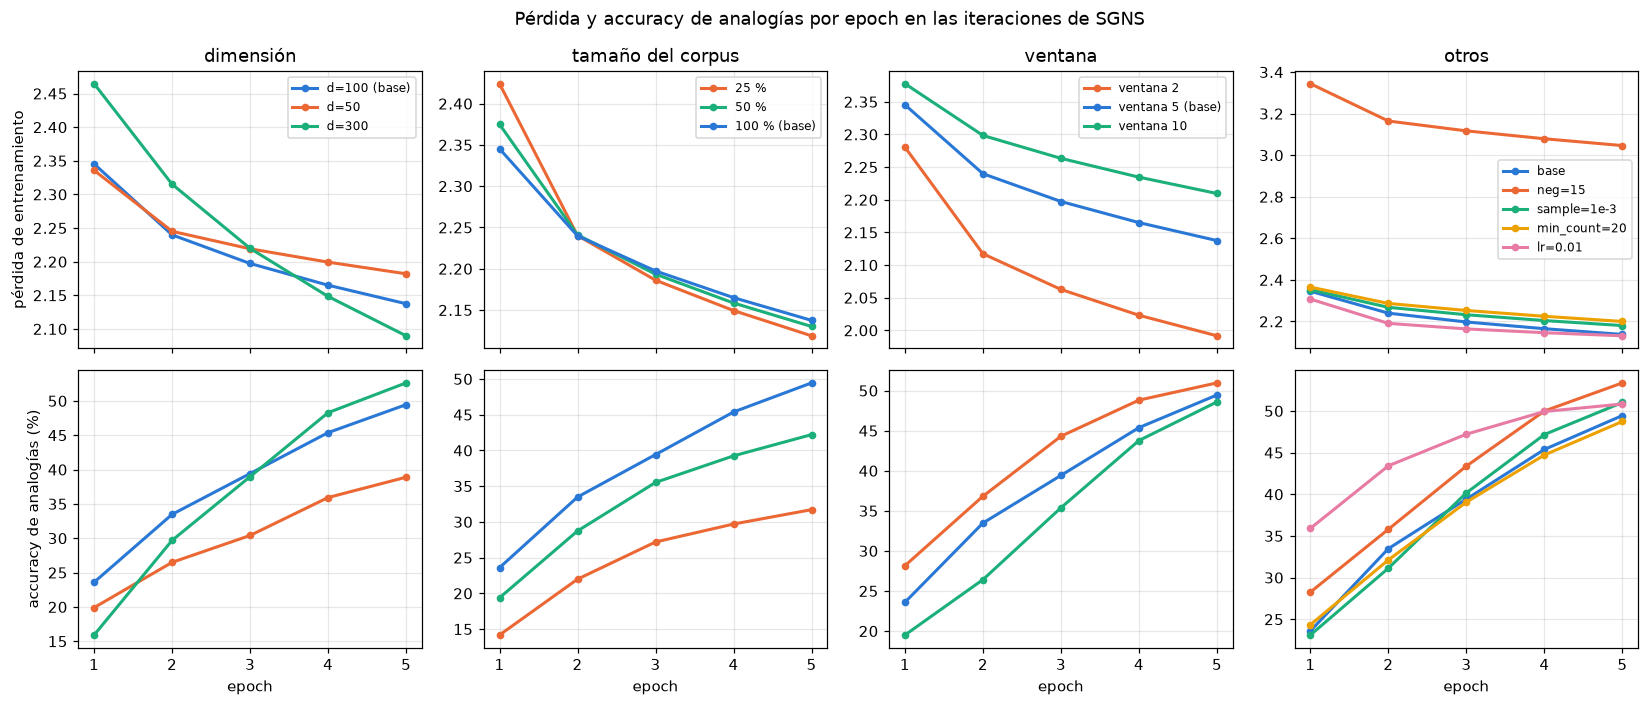

In [17]:
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GRUPOS_IT = {
    "dimensión": {"it01_base": "d=100 (base)", "it02_dim50": "d=50", "it03_dim300": "d=300"},
    "tamaño del corpus": {"it04_corpus25": "25 %", "it05_corpus50": "50 %", "it01_base": "100 % (base)"},
    "ventana": {"it06_ventana2": "ventana 2", "it01_base": "ventana 5 (base)", "it07_ventana10": "ventana 10"},
    "otros": {"it01_base": "base", "it08_neg15": "neg=15", "it09_sample1e-3": "sample=1e-3",
              "it10_mincount20": "min_count=20", "it11_lr0.01": "lr=0.01"},
}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for j, (grupo, miembros) in enumerate(GRUPOS_IT.items()):
    variantes = [n for n in miembros if n != "it01_base"]
    for n, etiqueta in miembros.items():
        h = pd.DataFrame(RES[n]["hist"])
        color = COLORES[0] if n == "it01_base" else COLORES[1 + variantes.index(n)]  # la base siempre en azul
        estilo = dict(color=color, lw=2, marker="o", ms=4, label=etiqueta)
        axes[0, j].plot(h["epoch"], h["perdida"], **estilo)
        axes[1, j].plot(h["epoch"], 100 * h["an_total"], **estilo)
    axes[0, j].set_title(grupo)
    axes[1, j].set_xlabel("epoch")
    axes[0, j].legend(fontsize=8)
axes[0, 0].set_ylabel("pérdida de entrenamiento")
axes[1, 0].set_ylabel("accuracy de analogías (%)")
fig.suptitle("Pérdida y accuracy de analogías por epoch en las iteraciones de SGNS")
fig.tight_layout(); fig.savefig("figures/curvas_iteraciones.png", dpi=200); plt.show()

**¿Una pérdida más baja implica siempre mejores embeddings?** No. La ventana 2 terminó con la pérdida más baja (1.99) y 51.0 % en analogías, mientras que neg=15 terminó con la más alta (3.05) y el mejor resultado (53.4 %). El corpus de 25 % cerró con menos pérdida que la base (2.12 contra 2.14) y 17.8 puntos menos en analogías, porque con menos texto el modelo se ajusta mejor a esos pares sin aprender más relaciones. La pérdida depende de la tarea que define cada configuración (número de negativos, distancia del contexto), así que solo sirve para comparar epochs de una misma iteración; ahí sí baja mientras las analogías suben.

In [18]:
# vecinos de las palabras de control al final de cada epoch (iteración base) y al final de cada iteración
vec_base = pd.DataFrame({h["epoch"]: {w: ", ".join(v) for w, v in h["vecinos"].items()} for h in RES["it01_base"]["hist"]}).T
vec_base.index.name = "epoch"
pd.DataFrame([{"iteración": r["nombre"], "epoch": h["epoch"], **{w: ", ".join(v) for w, v in h["vecinos"].items()}}
              for r in RES.values() for h in r["hist"]]).to_csv("results/vecinos_por_epoch.csv", index=False)
print("Iteración base, vecinos por epoch:")
display(vec_base)
print("Vecinos al final de cada iteración:")
pd.DataFrame({n: {w: ", ".join(v) for w, v in r["hist"][-1]["vecinos"].items()} for n, r in RES.items()}).T

Iteración base, vecinos por epoch:


,king,france,computer,good,january,run
epoch,,,,,,
1,"prince, ragnaill, guthfrithson, neógain, throne","spain, italy, britain, belgium, netherlands","software, simulation, interface, desktop, computers","bad, decent, commented, really, very","february, september, july, november, october","running, ran, runs, montclair-boonton, mauses"
2,"queen, prince, throne, guthfrithson, shalmaneser","austria, italy, belgium, spain, portugal","computers, software, desktop, technology, fault-tolerant","bad, pretty, think, happy, better","february, december, june, april, march","outing, running, runs, ran, trib"
3,"prince, throne, ruler, queen, ragnaill","netherlands, belgium, spain, italy, portugal","computers, software, technology, graphics, simulation","bad, pretty, perfect, kind, better","december, february, november, april, march","running, ran, runs, trib, 76-yard"
4,"throne, prince, queen, regent, kings","spain, italy, belgium, portugal, netherlands","computers, software, computing, technology, desktop","bad, better, decent, pretty, excellent","february, december, march, november, june","running, ran, runs, drive, 76-yard"
5,"prince, queen, throne, monarch, kings","spain, belgium, italy, netherlands, austria","computers, software, computing, desktop, simulation","bad, excellent, pretty, luck, decent","december, february, march, november, april","running, ran, runs, drive, trib"


Vecinos al final de cada iteración:


,king,france,computer,good,january,run
it01_base,"prince, queen, throne, monarch, kings","spain, belgium, italy, netherlands, austria","computers, software, computing, desktop, simulation","bad, excellent, pretty, luck, decent","december, february, march, november, april","running, ran, runs, drive, trib"
it02_dim50,"throne, prince, 1413, edward, regent","spain, italy, belgium, portugal, netherlands","computers, software, simulation, computing, desktop","better, decent, bad, pretty, easy","december, february, june, march, april","running, ran, runs, drive, 76-yard"
it03_dim300,"queen, throne, prince, son, ruler","italy, spain, germany, belgium, french","computers, software, graphics, hardware, console","bad, excellent, better, decent, poor","february, december, march, november, april","running, runs, ran, walk, drive"
it04_corpus25,"reign, prince, queen, kings, throne","spain, italy, belgium, germany, portugal","computers, software, graphics, hardware, gd-rom","bad, really, pretty, better, excellent","february, december, november, march, april","ran, runs, running, walk-off, two-run"
it05_corpus50,"throne, monarch, prince, queen, heir","spain, italy, belgium, netherlands, portugal","computers, software, mpi, computing, graphics","bad, pretty, excellent, very, really","december, february, november, march, april","running, runs, ran, drive, 76-yard"
it06_ventana2,"shalmaneser, prince, queen, monarch, arailt","spain, italy, belgium, netherlands, austria","computers, software, simulation, technology, hardware","bad, excellent, decent, poor, perfect","february, december, june, november, april","runs, running, ran, trib, mauses"
it07_ventana10,"throne, monarch, prince, heir, queen","belgium, spain, italy, portugal, french","computers, software, computing, hardware, real-time","pretty, very, bad, always, easy","february, december, march, november, april","running, runs, ran, drive, start"
it08_neg15,"queen, throne, prince, monarch, accession","spain, belgium, italy, portugal, germany","computers, software, computing, desktop, hardware","bad, excellent, pretty, luck, easy","february, december, march, november, april","running, runs, ran, drive, home"
it09_sample1e-3,"prince, monarch, queen, vi, throne","spain, italy, belgium, portugal, netherlands","computers, software, simulation, computing, interface","bad, decent, pretty, perfect, clever","february, december, november, march, april","runs, running, drive, ran, stretch"
it10_mincount20,"throne, prince, queen, vi, ruler","spain, italy, belgium, portugal, netherlands","computers, software, computing, interactive, real-time","bad, excellent, decent, pretty, better","december, february, november, march, april","running, runs, ran, drive, outing"


### 4.5 Word2Vec de gensim

Skip-gram (sg=1) con negative sampling sobre el mismo subconjunto y con los mismos dim, ventana, negativos, sample, min_count y epochs de la mejor iteración. La tasa de aprendizaje no es equivalente porque gensim usa SGD con alpha=0.025 decreciente; se dejan sus valores por defecto. El corpus se escribe como archivo de texto, una oración por línea, para usar `corpus_file`, que reparte el archivo entre hilos. En este CPU (8 núcleos P y 16 E) 12 hilos rindieron más que 32.

In [19]:
CFG_MEJOR = RES[MEJOR]["cfg"]
c_mejor = construir_corpus(CFG_MEJOR["frac"], CFG_MEJOR["min_count"])
CORPUS_TXT = f"data/wikitext103_{c_mejor['n_tokens'] // 1_000_000}M.txt"
if not os.path.exists(CORPUS_TXT):
    palabras = np.array(i2w_full, dtype=object)
    limites = np.concatenate([[0], cum_full[:c_mejor["n_sent"]]])
    with open(CORPUS_TXT, "w", encoding="utf-8") as f:
        for i in range(c_mejor["n_sent"]):
            f.write(" ".join(palabras[ids_full[limites[i]:limites[i + 1]]]) + "\n")
    del palabras


class MonitorGensim(CallbackAny2Vec):
    """Mismas métricas por epoch que en SGNS."""
    def __init__(self, ve):
        self.ve, self.hist, self.ep = ve, [], 0

    def on_epoch_begin(self, model):
        self.t0 = time.time()

    def on_epoch_end(self, model):
        t, self.ep = time.time() - self.t0, self.ep + 1
        E, w2i = torch.tensor(model.wv.vectors, device=DEV), model.wv.key_to_index
        an, _ = evaluar_analogias(self.ve.matriz(E, w2i), self.ve)
        ws, _ = spearman(E, w2i, WS353)
        self.hist.append({"iteracion": "gensim", "epoch": self.ep, "an_sem": an["sem"], "an_sin": an["sin"],
                          "an_total": an["total"], "wordsim": ws, "tiempo_s": t,
                          "vecinos": vecinos(E, model.wv.index_to_key, w2i)})
        print(f"gensim epoch {self.ep} | analogías sem {an['sem']:.3f} sin {an['sin']:.3f} total {an['total']:.3f} "
              f"| WordSim {ws:.3f} | {t:.1f} s")


monitor = MonitorGensim(VE)
CACHE_W2V = "data/w2v_gensim.model"
if os.path.exists(CACHE_W2V):
    w2v = Word2Vec.load(CACHE_W2V)
    monitor.hist, T_GENSIM = torch.load(CACHE_W2V + ".hist.pt", weights_only=False)
    for h in monitor.hist:
        print(f"gensim epoch {h['epoch']} | analogías sem {h['an_sem']:.3f} sin {h['an_sin']:.3f} total {h['an_total']:.3f} "
              f"| WordSim {h['wordsim']:.3f} | {h['tiempo_s']:.1f} s (desde {CACHE_W2V})")
else:
    t0 = time.time()
    w2v = Word2Vec(corpus_file=CORPUS_TXT, vector_size=CFG_MEJOR["dim"], window=CFG_MEJOR["window"],
                   negative=CFG_MEJOR["neg"], sample=CFG_MEJOR["sample"], min_count=CFG_MEJOR["min_count"],
                   sg=1, hs=0, epochs=CFG_MEJOR["epochs"], workers=12, seed=SEED, callbacks=[monitor])
    T_GENSIM = time.time() - t0
    w2v.callbacks = ()  # el monitor tiene tensores en GPU; no se guarda con el modelo
    w2v.save(CACHE_W2V)
    torch.save((monitor.hist, T_GENSIM), CACHE_W2V + ".hist.pt")
print(f"tiempo total gensim (incluye construir el vocabulario): {T_GENSIM:.0f} s")
print(f"vocabulario idéntico al de SGNS: {set(w2v.wv.index_to_key) == set(RES[MEJOR]['words'])} ({len(w2v.wv):,} palabras)")

gensim epoch 1 | analogías sem 0.137 sin 0.237 total 0.207 | WordSim 0.595 | 55.2 s


gensim epoch 2 | analogías sem 0.229 sin 0.335 total 0.303 | WordSim 0.652 | 57.4 s


gensim epoch 3 | analogías sem 0.334 sin 0.416 total 0.391 | WordSim 0.644 | 58.5 s


gensim epoch 4 | analogías sem 0.409 sin 0.481 total 0.459 | WordSim 0.658 | 56.8 s


gensim epoch 5 | analogías sem 0.449 sin 0.541 total 0.513 | WordSim 0.675 | 58.2 s
tiempo total gensim (incluye construir el vocabulario): 298 s
vocabulario idéntico al de SGNS: True (144,751 palabras)


### 4.6 GloVe preentrenado y modelos para las secciones siguientes

GloVe se usa tal cual. Los tres conjuntos se guardan como `KeyedVectors` para usar `most_similar` de gensim como referencia, y como tensores en GPU para la evaluación. Los vectores del mejor SGNS se guardan en `vectors/`.

In [20]:
kv_sgns = KeyedVectors(vector_size=CFG_MEJOR["dim"])
kv_sgns.add_vectors(RES[MEJOR]["words"], RES[MEJOR]["E"].numpy())
KV = {"SGNS": kv_sgns, "gensim": w2v.wv, "GloVe": glove}
MOD = {n: {"E": torch.tensor(kv.vectors, device=DEV), "words": kv.index_to_key, "w2i": kv.key_to_index}
       for n, kv in KV.items()}

filas = []
for n, m in MOD.items():
    an, _ = evaluar_analogias(VE.matriz(m["E"], m["w2i"]), VE)
    ws, n_ws = spearman(m["E"], m["w2i"], WS353)
    filas.append({"modelo": n, "V": len(m["words"]), "dim": m["E"].shape[1], "an. sem": an["sem"],
                  "an. sin": an["sin"], "an. total": an["total"], "WordSim": ws, "pares WordSim": n_ws})
display(pd.DataFrame(filas).set_index("modelo").round(3))
pd.DataFrame({n: {w: ", ".join(v) for w, v in vecinos(m["E"], m["words"], m["w2i"]).items()} for n, m in MOD.items()})

,V,dim,an. sem,an. sin,an. total,WordSim,pares WordSim
modelo,,,,,,,
SGNS,144751,100,0.515,0.542,0.534,0.673,353
gensim,144751,100,0.449,0.541,0.513,0.675,353
GloVe,400000,100,0.603,0.676,0.654,0.533,353


,SGNS,gensim,GloVe
king,"queen, throne, prince, monarch, accession","uncrowned, harthacnut, fitzempress, chlothar, villehardouin","prince, queen, son, brother, monarch"
france,"spain, belgium, italy, portugal, germany","italy, spain, belgium, portugal, netherlands","belgium, french, britain, spain, paris"
computer,"computers, software, computing, desktop, hardware","computers, edsac, computing, software, programmable","computers, software, technology, pc, hardware"
good,"bad, excellent, pretty, luck, easy","bad, enviable, excellent, natured, decent","better, sure, really, kind, very"
january,"february, december, march, november, april","december, february, march, april, july","december, october, february, november, september"
run,"running, runs, ran, drive, home","running, inside-the-park, ninth-inning, eighth-inning, 76-yard","running, runs, ran, out, go"


In [21]:
# vectores del mejor modelo: formato .kv de gensim; si pasan de 90 MB se guardan las palabras más frecuentes
n_max = min(len(kv_sgns), int(90e6 / (4 * kv_sgns.vector_size)))
kv_guardar = KeyedVectors(vector_size=kv_sgns.vector_size)
kv_guardar.add_vectors(kv_sgns.index_to_key[:n_max], kv_sgns.vectors[:n_max])
kv_guardar.save("vectors/sgns_mejor.kv")
print(f"guardadas {n_max:,} de {len(kv_sgns):,} palabras en vectors/sgns_mejor.kv")
print("carga: KeyedVectors.load('vectors/sgns_mejor.kv')")

guardadas 144,751 de 144,751 palabras en vectors/sgns_mejor.kv
carga: KeyedVectors.load('vectors/sgns_mejor.kv')


## 5. Verificación de la aritmética vectorial

### 5.1 Analogías individuales

`analogia(a, b, c, k)` resuelve "a es a b como c es a ?" con 3CosAdd: normaliza los vectores, calcula b - a + c, lo normaliza y devuelve las k palabras con mayor similitud coseno, sin contar a, b ni c. Primero se compara con `most_similar(positive=[b, c], negative=[a])` de gensim sobre el vocabulario completo de cada modelo. Para los resultados, la búsqueda se limita al vocabulario de evaluación compartido, así los tres modelos eligen entre las mismas 30,000 palabras.

In [22]:
_normas = {}


def normalizados(kv):
    if id(kv) not in _normas:
        _normas[id(kv)] = kv.vectors / np.linalg.norm(kv.vectors, axis=1, keepdims=True)
    return _normas[id(kv)]


def analogia(a, b, c, k=5, kv=None, vocab=None, excluir=True, respuesta=None):
    """a es a b como c es a ?  Devuelve top-k [(palabra, coseno)] y, si se da la respuesta, su rango y coseno."""
    En, w2i = normalizados(kv), kv.key_to_index
    idx = np.arange(len(kv)) if vocab is None else np.array([w2i[w] for w in vocab])
    q = En[w2i[b]] - En[w2i[a]] + En[w2i[c]]
    q = q / np.linalg.norm(q)
    sims = En[idx] @ q
    if excluir:
        sims[np.isin(idx, [w2i[a], w2i[b], w2i[c]])] = -np.inf
    top = np.argsort(-sims)[:k]
    res = [(kv.index_to_key[idx[i]], float(sims[i])) for i in top]
    if respuesta is None:
        return res
    j = int(np.where(idx == w2i[respuesta])[0][0])
    return res, int((sims > sims[j]).sum()) + 1, float(sims[j])


# verificación contra most_similar de gensim en el vocabulario completo
for n, kv in KV.items():
    iguales = True
    for a, b, c in [("man", "woman", "king"), ("france", "paris", "japan"), ("good", "better", "bad"), ("walk", "walked", "go")]:
        propio = analogia(a, b, c, 5, kv)
        ref = kv.most_similar(positive=[b, c], negative=[a], topn=5)
        iguales &= [w for w, _ in propio] == [w for w, _ in ref] and np.allclose([s for _, s in propio], [s for _, s in ref], atol=1e-5)
    print(f"{n}: coincide con most_similar en palabras y similitudes: {iguales}")

SGNS: coincide con most_similar en palabras y similitudes: True


gensim: coincide con most_similar en palabras y similitudes: True


GloVe: coincide con most_similar en palabras y similitudes: True


In [23]:
PROPIAS = [  # (tipo, a, b, c, respuesta esperada)
    ("género", "man", "woman", "king", "queen"), ("género", "boy", "girl", "brother", "sister"),
    ("género", "father", "mother", "son", "daughter"), ("género", "he", "she", "his", "her"),
    ("país-capital", "france", "paris", "italy", "rome"), ("país-capital", "japan", "tokyo", "germany", "berlin"),
    ("país-capital", "spain", "madrid", "russia", "moscow"),
    ("país-gentilicio", "france", "french", "germany", "german"), ("país-gentilicio", "italy", "italian", "japan", "japanese"),
    ("país-gentilicio", "china", "chinese", "spain", "spanish"),
    ("comparativo/superlativo", "good", "better", "bad", "worse"), ("comparativo/superlativo", "big", "bigger", "small", "smaller"),
    ("comparativo/superlativo", "fast", "fastest", "strong", "strongest"),
    ("tiempo verbal", "walk", "walked", "go", "went"), ("tiempo verbal", "run", "ran", "see", "saw"),
    ("tiempo verbal", "eat", "eating", "swim", "swimming"),
    ("plural", "car", "cars", "child", "children"), ("plural", "mouse", "mice", "man", "men"),
    ("plural", "city", "cities", "country", "countries"),
]
assert all(w in VE.pos for _, *ws in PROPIAS for w in ws)

filas, filas_top = [], []
for tipo, a, b, c, d in PROPIAS:
    fila = {"tipo": tipo, "analogía": f"{a} : {b} :: {c} : ?", "esperada": d}
    for n, kv in KV.items():
        top, rango, cos = analogia(a, b, c, 5, kv, vocab=EVAL_WORDS, respuesta=d)
        sin_excl = analogia(a, b, c, 1, kv, vocab=EVAL_WORDS, excluir=False)[0][0]
        fila.update({f"{n} top-1": top[0][0], f"{n} rango": rango, f"{n} cos": cos, f"{n} sin excluir": sin_excl})
        filas_top.append({"modelo": n, "analogía": fila["analogía"], "esperada": d, "rango": rango,
                          "cos respuesta": round(cos, 3), "top-5": ", ".join(f"{w} ({s:.3f})" for w, s in top)})
    filas.append(fila)
tabla_propias = pd.DataFrame(filas)
tabla_top5 = pd.DataFrame(filas_top)
tabla_propias.to_csv("results/analogias_propias.csv", index=False)
tabla_top5.to_csv("results/analogias_propias_top5.csv", index=False)

resumen = pd.DataFrame({n: {"acierto top-1 (%)": 100 * (tabla_propias[f"{n} rango"] == 1).mean(),
                            "en top-5 (%)": 100 * (tabla_propias[f"{n} rango"] <= 5).mean(),
                            "rango mediano": tabla_propias[f"{n} rango"].median(),
                            "coseno medio con b - a + c": tabla_propias[f"{n} cos"].mean()} for n in KV}).T
display(resumen.round(3))
tabla_top5.pivot(index="analogía", columns="modelo", values="top-5").loc[tabla_propias["analogía"]]

,acierto top-1 (%),en top-5 (%),rango mediano,coseno medio con b - a + c
SGNS,73.684,84.211,1.0,0.730
gensim,68.421,78.947,1.0,0.722
GloVe,84.211,94.737,1.0,0.838


modelo,GloVe,SGNS,gensim
analogía,,,
man : woman :: king : ?,"queen (0.770), monarch (0.684), throne (0.676), daughter (0.659), princess (0.652)","queen (0.741), consort (0.663), throne (0.661), marriage (0.645), mary (0.631)","queen (0.682), throne (0.681), mary (0.664), accession (0.663), consort (0.656)"
boy : girl :: brother : ?,"daughter (0.890), wife (0.884), father (0.877), cousin (0.867), son (0.864)","daughter (0.745), cousin (0.740), father (0.732), wife (0.721), husband (0.717)","cousin (0.735), father (0.717), son (0.710), daughter (0.706), wife (0.696)"
father : mother :: son : ?,"daughter (0.953), wife (0.887), sister (0.843), niece (0.820), husband (0.819)","daughter (0.893), wife (0.838), eldest (0.814), grandmother (0.790), daughters (0.787)","daughter (0.889), wife (0.837), eldest (0.816), grandson (0.769), childless (0.767)"
he : she :: his : ?,"her (0.985), mother (0.810), wife (0.790), my (0.778), herself (0.766)","her (0.954), husband (0.755), herself (0.744), mother (0.696), sister (0.682)","her (0.916), hers (0.662), herself (0.647), husband (0.620), half-sister (0.617)"
france : paris :: italy : ?,"rome (0.819), milan (0.738), naples (0.712), venice (0.702), turin (0.700)","vienna (0.716), venice (0.709), milan (0.708), berlin (0.691), rome (0.689)","vienna (0.763), munich (0.740), berlin (0.728), milan (0.717), lausanne (0.716)"
japan : tokyo :: germany : ?,"frankfurt (0.843), berlin (0.819), munich (0.730), paris (0.711), vienna (0.694)","berlin (0.803), frankfurt (0.716), munich (0.703), düsseldorf (0.697), budapest (0.694)","berlin (0.770), munich (0.748), düsseldorf (0.738), frankfurt (0.736), paris (0.731)"
spain : madrid :: russia : ?,"moscow (0.855), kiev (0.736), tehran (0.663), russian (0.658), ukraine (0.646)","moscow (0.721), helsinki (0.614), mikhail (0.598), russian (0.583), ukraine (0.582)","moscow (0.755), ukraine (0.709), munich (0.681), baku (0.678), warsaw (0.662)"
france : french :: germany : ?,"german (0.960), austrian (0.777), swiss (0.766), swedish (0.734), polish (0.726)","german (0.885), austrian (0.776), dutch (0.725), russian (0.703), germans (0.692)","german (0.845), austrian (0.777), russian (0.746), romanian (0.733), swedish (0.728)"
italy : italian :: japan : ?,"japanese (0.928), korean (0.731), chinese (0.682), tokyo (0.654), taiwanese (0.639)","japanese (0.843), taiwanese (0.631), tokyo (0.625), suzuki (0.615), chinese (0.610)","japanese (0.834), taiwanese (0.654), chinese (0.654), philippine (0.644), russian (0.636)"


Rango de la respuesta correcta y su similitud coseno con b - a + c para cada modelo:

In [24]:
cols = ["tipo", "analogía", "esperada"] + [f"{n} {x}" for n in KV for x in ["top-1", "rango", "cos"]]
tabla_propias[cols].round(3)

,tipo,analogía,esperada,SGNS top-1,SGNS rango,SGNS cos,gensim top-1,gensim rango,gensim cos,GloVe top-1,GloVe rango,GloVe cos
0,género,man : woman :: king : ?,queen,queen,1,0.741,queen,1,0.682,queen,1,0.770
1,género,boy : girl :: brother : ?,sister,daughter,11,0.670,cousin,6,0.693,daughter,6,0.840
2,género,father : mother :: son : ?,daughter,daughter,1,0.893,daughter,1,0.889,daughter,1,0.953
3,género,he : she :: his : ?,her,her,1,0.954,her,1,0.916,her,1,0.985
4,país-capital,france : paris :: italy : ?,rome,vienna,5,0.689,vienna,15,0.669,rome,1,0.819
5,país-capital,japan : tokyo :: germany : ?,berlin,berlin,1,0.803,berlin,1,0.770,frankfurt,2,0.819
6,país-capital,spain : madrid :: russia : ?,moscow,moscow,1,0.721,moscow,1,0.755,moscow,1,0.855
7,país-gentilicio,france : french :: germany : ?,german,german,1,0.885,german,1,0.845,german,1,0.960
8,país-gentilicio,italy : italian :: japan : ?,japanese,japanese,1,0.843,japanese,1,0.834,japanese,1,0.928
9,país-gentilicio,china : chinese :: spain : ?,spanish,spanish,1,0.798,spanish,1,0.812,spanish,1,0.890


**Sin excluir las palabras de la consulta.** Se repite la búsqueda dejando a, b y c como candidatos. La tabla muestra la primera palabra en las analogías propias y, para todo el benchmark, en qué proporción la primera es c, b, a, la respuesta correcta u otra palabra.

In [25]:
@torch.no_grad()
def primero_sin_excluir(E_eval, q, bloque=2048):
    En = F.normalize(E_eval.float(), dim=1)
    return torch.cat([((En[qq[:, 1]] - En[qq[:, 0]] + En[qq[:, 2]]) @ En.T).argmax(1) for qq in q.split(bloque)])


filas = {}
for n, m in MOD.items():
    p = primero_sin_excluir(VE.matriz(m["E"], m["w2i"]), VE.q)
    q = VE.q
    filas[n] = {"c": (p == q[:, 2]).float().mean().item(), "b": (p == q[:, 1]).float().mean().item(),
                "a": (p == q[:, 0]).float().mean().item(), "respuesta d": (p == q[:, 3]).float().mean().item()}
    filas[n]["otra"] = 1 - sum(filas[n].values())
tabla_sin_excl = 100 * pd.DataFrame(filas).T
tabla_sin_excl.to_csv("results/analogias_sin_excluir.csv")
print("Primera palabra sin excluir a, b, c en todo el benchmark (% de preguntas):")
display(tabla_sin_excl.round(1))
tabla_propias[["analogía", "esperada"] + [f"{n} sin excluir" for n in KV]]

Primera palabra sin excluir a, b, c en todo el benchmark (% de preguntas):


,c,b,a,respuesta d,otra
SGNS,85.6,4.3,0.0,9.2,0.9
gensim,84.9,5.0,0.0,9.0,1.2
GloVe,57.9,5.8,0.0,32.2,4.0


,analogía,esperada,SGNS sin excluir,gensim sin excluir,GloVe sin excluir
0,man : woman :: king : ?,queen,king,king,king
1,boy : girl :: brother : ?,sister,brother,brother,brother
2,father : mother :: son : ?,daughter,daughter,daughter,daughter
3,he : she :: his : ?,her,her,her,her
4,france : paris :: italy : ?,rome,paris,paris,rome
5,japan : tokyo :: germany : ?,berlin,berlin,berlin,frankfurt
6,spain : madrid :: russia : ?,moscow,moscow,moscow,moscow
7,france : french :: germany : ?,german,german,german,german
8,italy : italian :: japan : ?,japanese,japanese,japanese,japanese
9,china : chinese :: spain : ?,spanish,spanish,spanish,spanish


### 5.2 Evaluación sistemática

Los tres modelos responden las mismas preguntas de questions-words.txt dentro del vocabulario compartido de 30,000 palabras. Antes se comprueba que la evaluación vectorizada da el mismo resultado que `evaluate_word_analogies` de gensim sobre GloVe con `restrict_vocab=30000`.

In [26]:
ve_glove30k = VocabEval(glove.index_to_key[:30_000])
propio = evaluar_analogias(ve_glove30k.matriz(MOD["GloVe"]["E"], glove.key_to_index), ve_glove30k)[0]["total"]
ref = glove.evaluate_word_analogies(analogias_path, restrict_vocab=30_000)[0]
print(f"GloVe top 30,000: evaluación propia {propio:.4f} | gensim {ref:.4f}")

GloVe top 30,000: evaluación propia 0.6549 | gensim 0.6549


In [27]:
sec_q, sec_ev = np.array(SECCIONES), VE.sec
sem_q, sem_ev = np.isin(sec_q, list(SEMANTICAS)), np.isin(sec_ev, list(SEMANTICAS))
GRUPOS_CAT = {c: (sec_q == c, sec_ev == c) for c in CATEGORIAS}
GRUPOS_CAT.update({"semánticas": (sem_q, sem_ev), "sintácticas": (~sem_q, ~sem_ev),
                   "total": (np.ones(len(sec_q), bool), np.ones(len(sec_ev), bool))})
tabla_cat = pd.DataFrame({"evaluadas": {g: int(m_ev.sum()) for g, (_, m_ev) in GRUPOS_CAT.items()},
                          "total": {g: int(m_q.sum()) for g, (m_q, _) in GRUPOS_CAT.items()}})
tabla_cat["cobertura %"] = 100 * tabla_cat["evaluadas"] / tabla_cat["total"]
ACIERTOS = {}
for n, m in MOD.items():
    E_eval = VE.matriz(m["E"], m["w2i"])
    for metodo, nombre_m in [("add", "3CosAdd"), ("mul", "3CosMul")]:
        _, ok = evaluar_analogias(E_eval, VE, metodo)
        ACIERTOS[(n, nombre_m)] = ok
        tabla_cat[f"{n} {nombre_m}"] = {g: 100 * ok[m_ev].mean() for g, (_, m_ev) in GRUPOS_CAT.items()}
tabla_cat.to_csv("results/analogias_por_categoria.csv")
tabla_cat.round(1)

,evaluadas,total,cobertura %,SGNS 3CosAdd,SGNS 3CosMul,gensim 3CosAdd,gensim 3CosMul,GloVe 3CosAdd,GloVe 3CosMul
capital-common-countries,462,506,91.3,68.8,66.9,61.5,61.3,93.7,92.2
capital-world,1171,4524,25.9,62.3,57.9,53.5,50.1,86.3,83.8
currency,70,866,8.1,0.0,0.0,1.4,1.4,5.7,4.3
city-in-state,1689,2467,68.5,40.1,37.3,34.3,32.0,29.8,26.7
family,342,506,67.6,57.9,56.4,54.7,51.8,88.0,86.8
gram1-adjective-to-adverb,812,992,81.9,18.8,15.9,17.2,14.8,27.6,27.7
gram2-opposite,342,812,42.1,15.8,11.7,24.0,19.6,25.4,21.9
gram3-comparative,1332,1332,100.0,58.9,56.5,65.8,63.3,80.0,78.0
gram4-superlative,702,1122,62.6,33.2,33.5,34.9,35.2,60.8,61.1
gram5-present-participle,870,1056,82.4,43.0,38.7,43.1,39.3,72.1,71.5


**t-SNE.** Cerca de 500 palabras de 8 grupos temáticos, proyectadas con t-SNE (distancia coseno, perplejidad 30) desde el mejor SGNS. Para medir los grupos sin depender de la proyección, se calcula también la pureza de vecinos: la fracción de los 10 vecinos más cercanos de cada palabra, en el espacio original, que pertenecen a su mismo grupo.

514 palabras en 8 grupos
pureza de 10 vecinos: {'SGNS': np.float64(0.913), 'gensim': np.float64(0.917), 'GloVe': np.float64(0.909)}


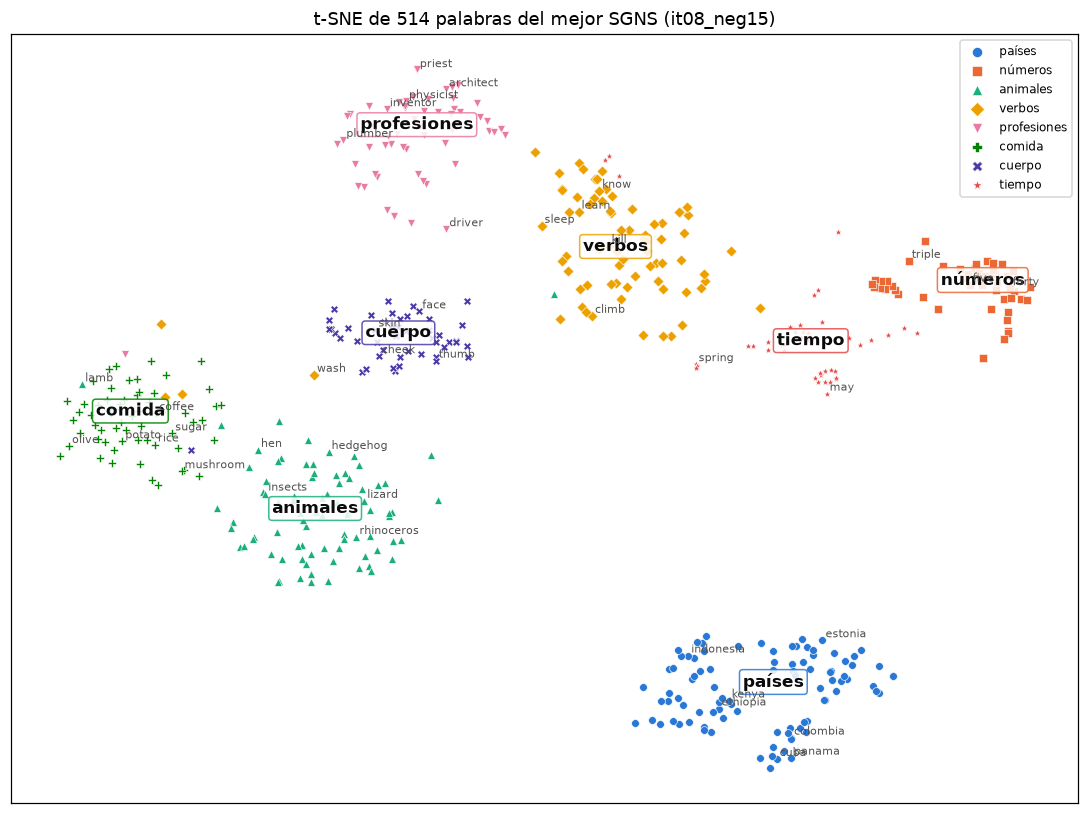

In [28]:
from sklearn.manifold import TSNE

GRUPOS_TSNE = {
    "países": "france germany italy spain portugal england ireland scotland netherlands belgium switzerland austria sweden "
              "norway denmark finland poland russia ukraine greece turkey egypt israel iran iraq india pakistan china japan "
              "korea vietnam thailand indonesia philippines australia canada mexico brazil argentina chile peru colombia cuba "
              "venezuela nigeria kenya ethiopia morocco algeria libya syria lebanon afghanistan hungary romania bulgaria serbia "
              "croatia zealand malaysia singapore iceland luxembourg estonia latvia lithuania belarus armenia "
              "kazakhstan mongolia nepal bangladesh cambodia jordan qatar kuwait yemen sudan somalia uganda tanzania "
              "zimbabwe ghana senegal tunisia ecuador bolivia uruguay jamaica haiti panama guatemala honduras",
    "números": "one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen seventeen "
               "eighteen nineteen twenty thirty forty fifty sixty seventy eighty ninety hundred thousand million billion "
               "first second third fourth fifth sixth seventh eighth ninth tenth dozen half zero hundreds thousands millions "
               "twice triple",
    "animales": "dog cat horse cow pig sheep goat duck goose rabbit mouse rat wolf fox bear lion tiger leopard elephant giraffe "
                "zebra monkey gorilla deer elk moose buffalo camel whale dolphin shark salmon trout eagle hawk owl crow sparrow "
                "parrot penguin snake lizard turtle frog crocodile spider bee ant butterfly beetle bat squirrel donkey mule "
                "pigeon swan seal otter beaver hedgehog cattle horses dogs wolves birds insects tortoise rhinoceros "
                "kangaroo koala panda raccoon badger lynx jaguar cheetah hyena antelope bison ox lamb hen",
    "verbos": "walk jump swim climb throw catch push pull carry lift build destroy create write read speak tell ask answer "
              "sing dance eat drink sleep wake think believe know understand remember forget learn teach buy sell pay give take "
              "bring send receive open close begin finish start stop win lose fight kill attack defend hide steal borrow "
              "cook wash cut break sit stand fall rise grow die live love hate want need help try leave arrive return enter",
    "profesiones": "doctor nurse teacher lawyer engineer scientist professor farmer soldier sailor pilot driver painter "
                   "writer poet singer actor actress musician composer architect banker merchant priest bishop judge "
                   "detective journalist editor photographer designer chef baker butcher carpenter plumber mechanic tailor "
                   "secretary manager surgeon dentist pharmacist accountant economist librarian historian philosopher "
                   "mathematician physicist chemist biologist novelist playwright sculptor dancer clerk inventor astronaut",
    "comida": "bread butter cheese milk egg meat beef pork rice wheat corn potato tomato onion garlic apple banana grape "
              "lemon strawberry cherry peach pear soup salad sugar salt pepper honey chocolate coffee tea wine beer juice "
              "cake pie pasta pizza sandwich cookie vinegar sausage bacon noodles fruit vegetables carrot cabbage lettuce "
              "beans peas mushroom olive oil flour cream yogurt steak ham shrimp oyster",
    "cuerpo": "head face eye ear nose mouth lip tooth teeth tongue neck shoulder arm elbow hand finger thumb chest stomach "
              "leg knee foot toe heart lung liver brain blood bone skin hair muscle wrist ankle hip spine kidney throat "
              "forehead cheek chin jaw eyebrow belly waist thigh heel palm",
    "tiempo": "january february march april may june july august september october november december monday tuesday "
              "wednesday thursday friday saturday sunday morning evening night afternoon midnight week month year decade "
              "century hour minute spring summer autumn winter today tomorrow yesterday weekend dawn dusk noon moment "
              "millennium",
}
pal_tsne, grp_tsne = [], []
for g, ws in GRUPOS_TSNE.items():
    for w in dict.fromkeys(ws.split()):
        if all(w in kv.key_to_index for kv in KV.values()) and w not in pal_tsne:
            pal_tsne.append(w); grp_tsne.append(g)
grp_tsne = np.array(grp_tsne)
print(f"{len(pal_tsne)} palabras en {len(GRUPOS_TSNE)} grupos")


def pureza_vecinos(kv, palabras, grupos, k=10):
    X = normalizados(kv)[[kv.key_to_index[w] for w in palabras]]
    S = X @ X.T
    np.fill_diagonal(S, -np.inf)
    vec = np.argsort(-S, axis=1)[:, :k]
    return (grupos[vec] == grupos[:, None]).mean()


print("pureza de 10 vecinos:", {n: round(pureza_vecinos(kv, pal_tsne, grp_tsne), 3) for n, kv in KV.items()})

X = normalizados(KV["SGNS"])[[KV["SGNS"].key_to_index[w] for w in pal_tsne]]
Y = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca", random_state=SEED).fit_transform(X)
MARCAS = ["o", "s", "^", "D", "v", "P", "X", "*"]
fig, ax = plt.subplots(figsize=(10, 7.5))
for i, g in enumerate(GRUPOS_TSNE):
    m = grp_tsne == g
    ax.scatter(Y[m, 0], Y[m, 1], s=26, color=COLORES[i], marker=MARCAS[i], label=g, edgecolors="white", linewidths=0.4)
    cx, cy = np.median(Y[m], axis=0)
    ax.annotate(g, (cx, cy), fontsize=11, weight="bold", ha="center", color="#0b0b0b",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=COLORES[i], alpha=0.85))
rng = np.random.default_rng(SEED)
for j in rng.choice(len(pal_tsne), 40, replace=False):
    ax.annotate(pal_tsne[j], Y[j], fontsize=7, color="#52514e", xytext=(2, 2), textcoords="offset points")
ax.legend(loc="best", fontsize=8, markerscale=1.3)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"t-SNE de {len(pal_tsne)} palabras del mejor SGNS ({MEJOR})")
fig.tight_layout(); fig.savefig("figures/tsne_sgns.png", dpi=200); plt.show()

In [29]:
X_g = normalizados(KV["SGNS"])[[KV["SGNS"].key_to_index[w] for w in pal_tsne]]
S_g = X_g @ X_g.T
np.fill_diagonal(S_g, -np.inf)
vec10 = np.argsort(-S_g, axis=1)[:, :10]
print("pureza de 10 vecinos por grupo (SGNS):", pd.Series((grp_tsne[vec10] == grp_tsne[:, None]).mean(1)).groupby(grp_tsne).mean().round(3).to_dict())
for w in ["third", "january", "monday", "bat", "fall", "cook"]:
    print(f"{w:>8} ({grp_tsne[pal_tsne.index(w)]}):", [pal_tsne[j] for j in np.argsort(-S_g[pal_tsne.index(w)])[:5]])

pureza de 10 vecinos por grupo (SGNS): {'animales': 0.88, 'comida': 0.924, 'cuerpo': 0.96, 'números': 0.947, 'países': 0.995, 'profesiones': 0.878, 'tiempo': 0.809, 'verbos': 0.873}
   third (números): ['fourth', 'second', 'fifth', 'sixth', 'seventh']
 january (tiempo): ['february', 'december', 'march', 'november', 'april']
  monday (tiempo): ['thursday', 'tuesday', 'sunday', 'saturday', 'friday']
     bat (animales): ['catch', 'duck', 'throw', 'leg', 'finger']
    fall (verbos): ['spring', 'break', 'autumn', 'rise', 'summer']
    cook (verbos): ['palm', 'baker', 'pizza', 'farmer', 'chef']


Se forman los ocho grupos esperados. Dentro de números, los ordinales forman un subgrupo (sus 5 vecinos más cercanos son otros ordinales) y dentro de tiempo los meses quedan separados de los días de la semana. Las palabras ambiguas se ubican según su sentido más frecuente en Wikipedia: los vecinos de "bat" son "catch" y "throw" (sentido deportivo), los de "fall" son "spring" y "autumn", y los de "cook" son "baker" y "chef". En el espacio original, 91 % de los 10 vecinos más cercanos de cada palabra pertenecen a su mismo grupo; países llega a 99.5 % y tiempo, el grupo más mezclado, a 80.9 %.

### 5.3 Paralelismo de los vectores diferencia

Si la aritmética fuera exacta, todos los vectores diferencia de una relación (por ejemplo paris - france, rome - italy, tokyo - japan) serían paralelos. Para cada categoría se toman los pares únicos (a, b) de las preguntas evaluadas, se calcula b - a con vectores normalizados y se promedia la similitud coseno entre todos los pares de diferencias. La referencia es el mismo cálculo con 300 pares de palabras al azar del vocabulario de evaluación.

In [30]:
def paralelismo(kv, pares):
    En, w2i = normalizados(kv), kv.key_to_index
    D = np.stack([En[w2i[b]] - En[w2i[a]] for a, b in pares])
    D = D / np.linalg.norm(D, axis=1, keepdims=True)
    S = D @ D.T
    return S[np.triu_indices(len(pares), 1)].mean()


q_np = VE.q.cpu().numpy()
PARES_CAT = {}
for cat in CATEGORIAS:
    filas_q = q_np[VE.sec == cat]
    pares = {(VE.words[a], VE.words[b]) for a, b, _, _ in filas_q} | {(VE.words[c], VE.words[d]) for _, _, c, d in filas_q}
    PARES_CAT[cat] = sorted(pares)
rng = np.random.default_rng(SEED)
pares_azar = [tuple(rng.choice(EVAL_WORDS, 2, replace=False)) for _ in range(300)]

tabla_par = pd.DataFrame({n: {cat: paralelismo(kv, PARES_CAT[cat]) for cat in CATEGORIAS} for n, kv in KV.items()})
tabla_par.insert(0, "pares", [len(PARES_CAT[c]) for c in CATEGORIAS])
tabla_par.loc["promedio categorías"] = tabla_par.loc[CATEGORIAS].mean()
tabla_par.loc["pares al azar"] = [300] + [paralelismo(kv, pares_azar) for kv in KV.values()]
tabla_par.to_csv("results/paralelismo.csv")

corr = {n: spearmanr(tabla_par.loc[CATEGORIAS, n], tabla_cat.loc[CATEGORIAS, f"{n} 3CosAdd"]).correlation for n in KV}
print("Spearman entre paralelismo y accuracy 3CosAdd por categoría:", {n: round(v, 3) for n, v in corr.items()})
tabla_par.round(3)

Spearman entre paralelismo y accuracy 3CosAdd por categoría: {'SGNS': np.float64(0.512), 'gensim': np.float64(0.697), 'GloVe': np.float64(0.895)}


,pares,SGNS,gensim,GloVe
capital-common-countries,22.0,0.348,0.362,0.586
capital-world,59.0,0.281,0.288,0.557
currency,9.0,0.220,0.211,0.256
city-in-state,56.0,0.197,0.212,0.341
family,19.0,0.273,0.272,0.507
gram1-adjective-to-adverb,29.0,0.137,0.137,0.271
gram2-opposite,19.0,0.108,0.117,0.227
gram3-comparative,37.0,0.305,0.322,0.424
gram4-superlative,27.0,0.299,0.299,0.465
gram5-present-participle,30.0,0.176,0.172,0.319


## 6. Pipeline end-to-end: clasificación de AG News

Texto, tokens, vectores, modelo y salida. AG News se tokeniza con el mismo `tokenizar` de la sección 2. Del entrenamiento se separa 10 % estratificado como validación y el test oficial (7,600 noticias) queda para la evaluación final.

Para cada conjunto de embeddings, el vocabulario del clasificador son las palabras de AG News que existen en ese conjunto; las demás nunca se consultan, así que el resultado es el mismo que con la tabla completa. Los embeddings aleatorios usan las palabras del split de entrenamiento con al menos 2 apariciones. Los tokens fuera del vocabulario se descartan y un documento sin tokens conocidos se representa con `<unk>`.

In [31]:
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

CLASES = news["train"].features["label"].names
docs_train = [tokenizar(t) for t in news["train"]["text"][:]]
docs_test = [tokenizar(t) for t in news["test"]["text"][:]]
y_train_all = np.array(news["train"]["label"][:])
y_test = np.array(news["test"]["label"][:])
IDX_TR, IDX_VA = train_test_split(np.arange(len(docs_train)), test_size=0.1, stratify=y_train_all, random_state=SEED)
print(f"entrenamiento {len(IDX_TR):,} | validación {len(IDX_VA):,} | test {len(docs_test):,} | clases {CLASES}")
print(f"tokens por noticia: media {np.mean([len(d) for d in docs_train]):.1f}, máximo {max(len(d) for d in docs_train)}")

cnt_ag = Counter(t for d in docs_train + docs_test for t in d)
VOCAB_ALEATORIO = {w for w, c in Counter(t for i in IDX_TR for t in docs_train[i]).items() if c >= 2}
vocabs_oov = {"SGNS": KV["SGNS"].key_to_index, "gensim": KV["gensim"].key_to_index, "GloVe": glove.key_to_index,
              "aleatorio (train, min 2)": VOCAB_ALEATORIO}
total_ag = sum(cnt_ag.values())
tabla_oov = pd.DataFrame({n: {"% tokens fuera de vocabulario": 100 * sum(c for w, c in cnt_ag.items() if w not in v) / total_ag,
                              "% tipos fuera de vocabulario": 100 * sum(1 for w in cnt_ag if w not in v) / len(cnt_ag)}
                          for n, v in vocabs_oov.items()}).T
tabla_oov.to_csv("results/oov_agnews.csv")
tabla_oov.round(2)

entrenamiento 108,000 | validación 12,000 | test 7,600 | clases ['World', 'Sports', 'Business', 'Sci/Tech']
tokens por noticia: media 38.1, máximo 181


,% tokens fuera de vocabulario,% tipos fuera de vocabulario
SGNS,2.87,42.23
gensim,2.87,42.23
GloVe,1.08,23.42
"aleatorio (train, min 2)",0.84,42.58


### 6.1 Baseline: TF-IDF y regresión logística

Unigramas y bigramas con frecuencia de documento mínima 2 y TF sublineal. C se elige con el F1 macro de validación.

In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


def metricas(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, p), "precision": pr, "recall": rc, "f1": f1}


def unigramas_bigramas(doc):
    return doc + [a + " " + b for a, b in zip(doc, doc[1:])]


def entrenar_tfidf(idx_entr, Cs=(2, 8, 32)):
    t0 = time.time()
    vec = TfidfVectorizer(analyzer=unigramas_bigramas, min_df=2, sublinear_tf=True)
    Xtr = vec.fit_transform([docs_train[i] for i in idx_entr])
    Xva = vec.transform([docs_train[i] for i in IDX_VA])
    mejor = None
    for C in Cs:
        lr = LogisticRegression(C=C, max_iter=3000).fit(Xtr, y_train_all[idx_entr])
        m = metricas(y_train_all[IDX_VA], lr.predict(Xva))
        if mejor is None or m["f1"] > mejor[2]["f1"]:
            mejor = (C, lr, m)
    C, lr, m = mejor
    n_par = lr.coef_.size + lr.intercept_.size
    return {"vec": vec, "modelo": lr, "C": C, "val": m, "params": n_par, "tiempo_s": time.time() - t0}


TFIDF = entrenar_tfidf(IDX_TR)
print(f"C={TFIDF['C']} | {len(TFIDF['vec'].vocabulary_):,} rasgos | validación {TFIDF['val']} | {TFIDF['tiempo_s']:.0f} s")

C=8 | 424,368 rasgos | validación {'accuracy': 0.9269166666666667, 'precision': 0.9267542696496155, 'recall': 0.9269166666666667, 'f1': 0.926750371769747} | 80 s


### 6.2 EmbeddingBag (promedio) + MLP

El mismo clasificador para todas las inicializaciones: `nn.EmbeddingBag(mode="mean")` con entrada 1D y offsets, seguido de Linear(d, 256), ReLU, Dropout(0.3) y Linear(256, 4). Adam con lr=1e-3, batches de 256, hasta 40 epochs y parada temprana con paciencia de 5 epochs sobre el F1 macro de validación; se conservan los pesos del mejor epoch.

In [33]:
class ClasificadorBolsa(nn.Module):
    def __init__(self, V, d, pesos=None, congelar=False, oculta=256, n_clases=4, dropout=0.3):
        super().__init__()
        if pesos is None:
            self.emb = nn.EmbeddingBag(V, d, mode="mean", padding_idx=0)
        else:
            self.emb = nn.EmbeddingBag.from_pretrained(pesos, freeze=congelar, mode="mean", padding_idx=0)
        self.mlp = nn.Sequential(nn.Linear(d, oculta), nn.ReLU(), nn.Dropout(dropout), nn.Linear(oculta, n_clases))

    def forward(self, tokens, offsets):
        return self.mlp(self.emb(tokens, offsets))


class Codificados:
    """Documentos como un tensor 1D de índices más inicio y largo de cada uno, todo en GPU."""
    def __init__(self, docs, w2i):
        ids = [[w2i[t] for t in d if t in w2i] or [1] for d in docs]  # 1 = <unk>
        self.largo = torch.tensor([len(x) for x in ids], device=DEV)
        self.inicio = torch.cumsum(self.largo, 0) - self.largo
        self.tok = torch.tensor([t for x in ids for t in x], device=DEV)

    def batch(self, idx):
        L = self.largo[idx]
        offsets = torch.cumsum(L, 0) - L
        total = int(L.sum())
        pos = torch.repeat_interleave(self.inicio[idx] - offsets, L, output_size=total) + torch.arange(total, device=DEV)
        return self.tok[pos], offsets


def vocab_y_pesos(nombre, idx_entr=None):
    """Vocabulario del clasificador (<pad>=0, <unk>=1) y matriz inicial, o None si es aleatorio."""
    if nombre == "aleatorio":
        cnt = Counter(t for i in idx_entr for t in docs_train[i])
        palabras = sorted(w for w, c in cnt.items() if c >= 2)
        return {w: i for i, w in enumerate(["<pad>", "<unk>"] + palabras)}, None
    kv = KV[nombre]
    palabras = sorted(w for w in cnt_ag if w in kv.key_to_index)
    pesos = np.zeros((len(palabras) + 2, kv.vector_size), dtype=np.float32)
    pesos[2:] = kv.vectors[[kv.key_to_index[w] for w in palabras]]
    return {w: i for i, w in enumerate(["<pad>", "<unk>"] + palabras)}, torch.tensor(pesos)


@torch.no_grad()
def predecir_clf(modelo, enc, idx, bloque=4096):
    modelo.eval()
    return torch.cat([modelo(*enc.batch(b)) for b in torch.as_tensor(idx, device=DEV).split(bloque)])


Y_TR_ALL = torch.tensor(y_train_all, device=DEV)


def entrenar_clf(nombre, init, congelar=False, idx_entr=IDX_TR, max_epochs=40, paciencia=5, lr=1e-3, batch=256,
                 d_aleatorio=100, verbose=True):
    torch.manual_seed(SEED)
    w2i, pesos = vocab_y_pesos(init, idx_entr)
    enc_tr, enc_te = Codificados(docs_train, w2i), Codificados(docs_test, w2i)
    d = d_aleatorio if pesos is None else pesos.shape[1]
    modelo = ClasificadorBolsa(len(w2i), d, pesos, congelar).to(DEV)
    entrenables = [p for p in modelo.parameters() if p.requires_grad]
    opt = torch.optim.Adam(entrenables, lr=lr)
    idx_t = torch.as_tensor(idx_entr, device=DEV)
    hist, mejor_f1, mejor_estado, sin_mejora, t0 = [], -1, None, 0, time.time()
    for ep in range(1, max_epochs + 1):
        modelo.train()
        suma, n = 0.0, 0
        for b in idx_t[torch.randperm(len(idx_t), device=DEV)].split(batch):
            loss = F.cross_entropy(modelo(*enc_tr.batch(b)), Y_TR_ALL[b])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            suma += loss.item() * len(b); n += len(b)
        logits = predecir_clf(modelo, enc_tr, IDX_VA)
        loss_va = F.cross_entropy(logits, Y_TR_ALL[IDX_VA]).item()
        m = metricas(y_train_all[IDX_VA], logits.argmax(1).cpu().numpy())
        hist.append({"epoch": ep, "loss_train": suma / n, "loss_val": loss_va, **m})
        if m["f1"] > mejor_f1:
            mejor_f1, sin_mejora = m["f1"], 0
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    t_total = time.time() - t0
    modelo.load_state_dict(mejor_estado)
    h = pd.DataFrame(hist)
    mejor = h.loc[h["f1"].idxmax()]
    res = {"nombre": nombre, "init": init, "congelar": congelar, "modelo": modelo, "enc_te": enc_te, "hist": h,
           "val": {k: mejor[k] for k in ["accuracy", "precision", "recall", "f1"]}, "mejor_epoch": int(mejor["epoch"]),
           "params": sum(p.numel() for p in modelo.parameters()), "entrenables": sum(p.numel() for p in entrenables),
           "tiempo_s": t_total, "V": len(w2i)}
    if verbose:
        print(f"{nombre:<20} V={len(w2i):>7,} | epochs {len(h):>2} (mejor {res['mejor_epoch']:>2}) | "
              f"val acc {mejor['accuracy']:.4f} F1 {mejor['f1']:.4f} | {t_total:.0f} s")
    return res


CLF = {"aleatorio": entrenar_clf("aleatorio", "aleatorio")}
for init in ["SGNS", "gensim", "GloVe"]:
    for congelar in [True, False]:
        nombre = f"{init} {'congelado' if congelar else 'fine-tuning'}"
        CLF[nombre] = entrenar_clf(nombre, init, congelar)

aleatorio            V= 49,238 | epochs 12 (mejor  7) | val acc 0.9142 F1 0.9140 | 11 s


SGNS congelado       V= 49,539 | epochs 40 (mejor 37) | val acc 0.9047 F1 0.9045 | 24 s


SGNS fine-tuning     V= 49,539 | epochs  8 (mejor  3) | val acc 0.9212 F1 0.9211 | 7 s


gensim congelado     V= 49,539 | epochs 38 (mejor 33) | val acc 0.8992 F1 0.8990 | 23 s


gensim fine-tuning   V= 49,539 | epochs  7 (mejor  2) | val acc 0.9203 F1 0.9202 | 6 s


GloVe congelado      V= 65,670 | epochs 40 (mejor 37) | val acc 0.9135 F1 0.9134 | 24 s


GloVe fine-tuning    V= 65,670 | epochs  9 (mejor  4) | val acc 0.9239 F1 0.9237 | 9 s


,accuracy,precision,recall,f1,parámetros,entrenables,tiempo s,mejor epoch
modelo,,,,,,,,
TF-IDF + LR,0.9269,0.9268,0.9269,0.9268,1697476,1697476,79.8648,NaN
aleatorio,0.9142,0.9140,0.9142,0.9140,4950684,4950684,10.7476,7.0
SGNS congelado,0.9047,0.9046,0.9047,0.9045,4980784,26884,23.6249,37.0
SGNS fine-tuning,0.9212,0.9213,0.9212,0.9211,4980784,4980784,7.0882,3.0
gensim congelado,0.8992,0.8990,0.8992,0.8990,4980784,26884,22.9557,33.0
gensim fine-tuning,0.9202,0.9205,0.9202,0.9202,4980784,4980784,6.1645,2.0
GloVe congelado,0.9135,0.9137,0.9135,0.9134,6593884,26884,23.9261,37.0
GloVe fine-tuning,0.9239,0.9247,0.9239,0.9237,6593884,6593884,9.1053,4.0


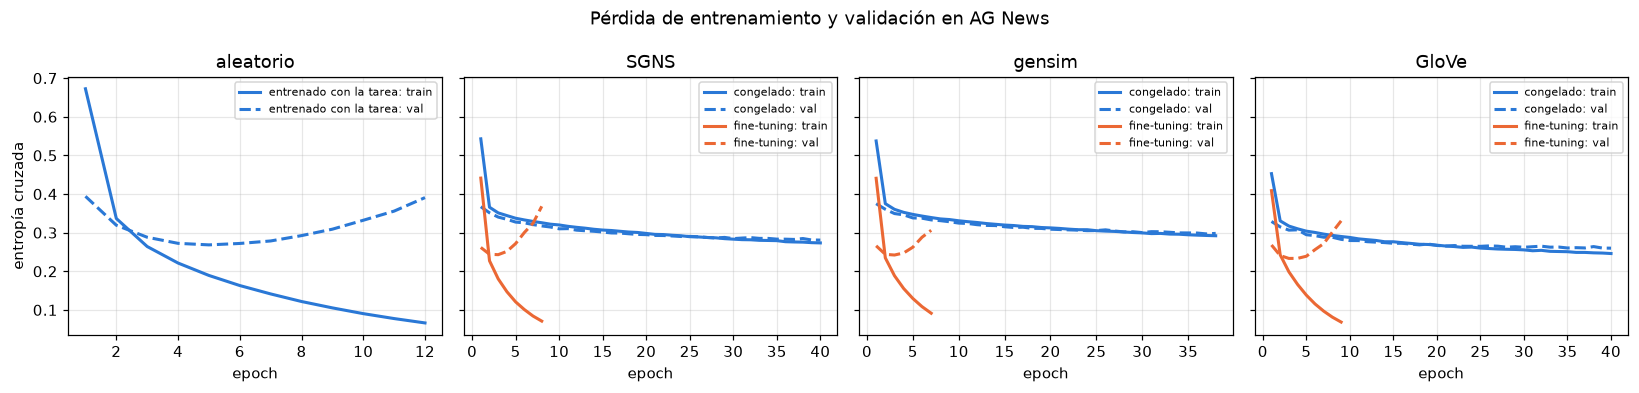

In [34]:
filas = [{"modelo": "TF-IDF + LR", **TFIDF["val"], "parámetros": TFIDF["params"], "entrenables": TFIDF["params"],
          "tiempo s": TFIDF["tiempo_s"], "mejor epoch": None}]
for n, r in CLF.items():
    filas.append({"modelo": n, **r["val"], "parámetros": r["params"], "entrenables": r["entrenables"],
                  "tiempo s": r["tiempo_s"], "mejor epoch": r["mejor_epoch"]})
tabla_val = pd.DataFrame(filas).set_index("modelo")
tabla_val.to_csv("results/clasificacion_validacion.csv")
display(tabla_val.round(4))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, init in zip(axes, ["aleatorio", "SGNS", "gensim", "GloVe"]):
    variantes = [n for n in CLF if CLF[n]["init"] == init]
    for k, n in enumerate(variantes):
        h = CLF[n]["hist"]
        etiqueta = n.replace(init, "").strip() or "entrenado con la tarea"
        ax.plot(h["epoch"], h["loss_train"], color=COLORES[k], lw=2, label=f"{etiqueta}: train")
        ax.plot(h["epoch"], h["loss_val"], color=COLORES[k], lw=2, ls="--", label=f"{etiqueta}: val")
    ax.set_title(init); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel("entropía cruzada")
fig.suptitle("Pérdida de entrenamiento y validación en AG News")
fig.tight_layout(); fig.savefig("figures/clasificacion_perdidas.png", dpi=200); plt.show()

### 6.3 Evaluación final en test

Se elige la mejor variante de cada inicialización por F1 de validación y se evalúa una sola vez en test, junto con el baseline.

,accuracy,precision,recall,f1
TF-IDF + LR,0.9216,0.9214,0.9216,0.9214
aleatorio,0.9068,0.9067,0.9068,0.9067
SGNS fine-tuning,0.9141,0.9142,0.9141,0.9141
gensim fine-tuning,0.9134,0.9138,0.9134,0.9133
GloVe fine-tuning,0.9204,0.9213,0.9204,0.9203


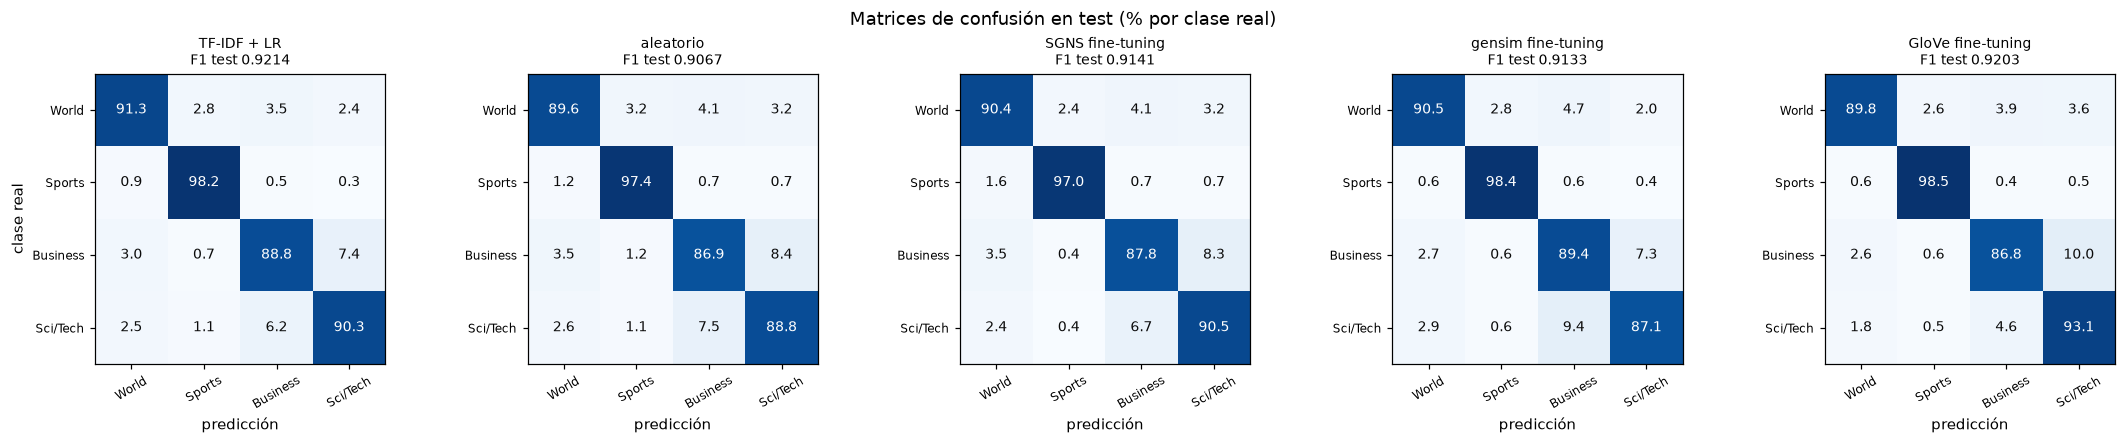

In [35]:
MEJOR_CLF = {}
for init in ["aleatorio", "SGNS", "gensim", "GloVe"]:
    variantes = [n for n in CLF if CLF[n]["init"] == init]
    MEJOR_CLF[init] = max(variantes, key=lambda n: CLF[n]["val"]["f1"])

PRED_TEST = {"TF-IDF + LR": TFIDF["modelo"].predict(TFIDF["vec"].transform(docs_test))}
for init, n in MEJOR_CLF.items():
    PRED_TEST[n] = predecir_clf(CLF[n]["modelo"], CLF[n]["enc_te"], np.arange(len(docs_test))).argmax(1).cpu().numpy()
tabla_test = pd.DataFrame({n: metricas(y_test, p) for n, p in PRED_TEST.items()}).T
tabla_test.to_csv("results/clasificacion_test.csv")
display(tabla_test.round(4))

fig, axes = plt.subplots(1, len(PRED_TEST), figsize=(4 * len(PRED_TEST), 3.9))
for ax, (n, p) in zip(axes, PRED_TEST.items()):
    cm = confusion_matrix(y_test, p, normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i, j]:.1f}", ha="center", va="center", fontsize=9, color="white" if cm[i, j] > 60 else "#0b0b0b")
    ax.set_xticks(range(4), CLASES, rotation=30, fontsize=8); ax.set_yticks(range(4), CLASES, fontsize=8)
    ax.set_title(f"{n}\nF1 test {tabla_test.loc[n, 'f1']:.4f}", fontsize=9); ax.grid(False)
    ax.set_xlabel("predicción")
axes[0].set_ylabel("clase real")
fig.suptitle("Matrices de confusión en test (% por clase real)")
fig.tight_layout(); fig.savefig("figures/matrices_confusion.png", dpi=200); plt.show()

### 6.4 SimLex-999

SimLex-999 mide similitud y no asociación: "coffee" y "cup" están relacionadas pero no son similares. Se reservó para esta evaluación final.

In [36]:
SIMILITUD = {}
for n, m in MOD.items():
    ws, n_ws = spearman(m["E"], m["w2i"], WS353)
    sl, n_sl = spearman(m["E"], m["w2i"], SIMLEX)
    SIMILITUD[n] = {"WordSim-353": ws, "pares WS": n_ws, "SimLex-999": sl, "pares SL": n_sl}
tabla_sim = pd.DataFrame(SIMILITUD).T
tabla_sim.to_csv("results/similitud.csv")
tabla_sim.round(3)

,WordSim-353,pares WS,SimLex-999,pares SL
SGNS,0.673,353.0,0.280,995.0
gensim,0.675,353.0,0.314,995.0
GloVe,0.533,353.0,0.298,999.0


### 6.5 F1 de test contra fracción de datos de entrenamiento

Cada inicialización se entrena con 1 %, 5 %, 10 %, 25 %, 50 % y 100 % del split de entrenamiento (submuestras estratificadas). La validación es la misma en todos los casos. Con menos datos hay menos pasos por epoch, así que el máximo de epochs crece como 40 / sqrt(fracción), con tope de 200.

In [37]:
FRACCIONES = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0]
VARIANTES_CURVA = [("aleatorio", "aleatorio", False), ("SGNS congelado", "SGNS", True), ("SGNS fine-tuning", "SGNS", False),
                   ("GloVe congelado", "GloVe", True), ("GloVe fine-tuning", "GloVe", False)]
filas = []
for f in FRACCIONES:
    t0 = time.time()
    if f == 1.0:
        idx = IDX_TR
    else:
        idx, _ = train_test_split(IDX_TR, train_size=f, stratify=y_train_all[IDX_TR], random_state=SEED)
    tf = TFIDF if f == 1.0 else entrenar_tfidf(idx)
    p = tf["modelo"].predict(tf["vec"].transform(docs_test))
    filas.append({"fracción": f, "n": len(idx), "modelo": "TF-IDF + LR", "f1_test": metricas(y_test, p)["f1"]})
    for nombre, init, congelar in VARIANTES_CURVA:
        if f == 1.0:
            r = CLF[nombre]
        else:
            r = entrenar_clf(nombre, init, congelar, idx_entr=idx, max_epochs=int(min(200, round(40 / f ** 0.5))), verbose=False)
        p = predecir_clf(r["modelo"], r["enc_te"], np.arange(len(docs_test))).argmax(1).cpu().numpy()
        filas.append({"fracción": f, "n": len(idx), "modelo": nombre, "f1_test": metricas(y_test, p)["f1"],
                      "epochs": len(r["hist"])})
        if f != 1.0:
            del r
    print(f"fracción {f:>5}: {len(idx):>6,} noticias | {time.time() - t0:.0f} s")
tabla_frac = pd.DataFrame(filas)
tabla_frac.to_csv("results/f1_vs_fraccion.csv", index=False)
torch.cuda.empty_cache()
tabla_frac.pivot(index="fracción", columns="modelo", values="f1_test").round(4)

fracción  0.01:  1,080 noticias | 10 s


fracción  0.05:  5,400 noticias | 14 s


fracción   0.1: 10,800 noticias | 19 s


fracción  0.25: 27,000 noticias | 50 s


fracción   0.5: 54,000 noticias | 88 s


fracción   1.0: 108,000 noticias | 0 s


modelo,GloVe congelado,GloVe fine-tuning,SGNS congelado,SGNS fine-tuning,TF-IDF + LR,aleatorio
fracción,,,,,,
0.01,0.8696,0.8716,0.8588,0.8672,0.8169,0.7191
0.05,0.8841,0.8895,0.8753,0.8873,0.8754,0.8157
0.10,0.8842,0.9003,0.8778,0.8968,0.8877,0.8424
0.25,0.8972,0.9077,0.8871,0.9017,0.9039,0.8697
0.50,0.9015,0.9140,0.8935,0.9100,0.9110,0.8899
1.00,0.9072,0.9203,0.8979,0.9141,0.9214,0.9067


## 7. Comparación de resultados

Para GloVe, el tiempo y el hardware son los reportados por Pennington et al. (2014): construir la matriz de co-ocurrencia de 6 mil millones de tokens tomó 85 minutos en un hilo de un servidor con dos Xeon E5-2658 a 2.1 GHz, y cada iteración de entrenamiento con d=300 tomó 14 minutos usando sus 32 núcleos. Para d menor a 300 usaron 50 iteraciones.

In [38]:
t_sgns = sum(h["tiempo_s"] for h in RES[MEJOR]["hist"])
t_gensim = sum(h["tiempo_s"] for h in monitor.hist)
f1_test = {"SGNS": tabla_test.loc[MEJOR_CLF["SGNS"], "f1"], "gensim": tabla_test.loc[MEJOR_CLF["gensim"], "f1"],
           "GloVe": tabla_test.loc[MEJOR_CLF["GloVe"], "f1"]}
comp = {}
for n in ["SGNS", "gensim", "GloVe"]:
    fila = {"tokens del corpus": f"{RES[MEJOR]['n_tokens']:,}" if n != "GloVe" else "6,000,000,000",
            "vocabulario": f"{len(KV[n]):,}", "dimensión": KV[n].vector_size,
            "tiempo de entrenamiento": {"SGNS": f"{t_sgns / 60:.1f} min ({CFG_MEJOR['epochs']} epochs)",
                                        "gensim": f"{t_gensim / 60:.1f} min ({CFG_MEJOR['epochs']} epochs)",
                                        "GloVe": "85 min para X + 14 min por iteración (d=300)"}[n],
            "hardware": {"SGNS": GPU, "gensim": f"{CPU}, 12 hilos", "GloVe": "2 x Xeon E5-2658 2.1 GHz, 32 núcleos"}[n]}
    for metodo in ["3CosAdd", "3CosMul"]:
        for g in ["semánticas", "sintácticas", "total"]:
            fila[f"analogías {g} {metodo} (%)"] = round(tabla_cat.loc[g, f"{n} {metodo}"], 1)
    fila["Spearman WordSim-353"] = round(SIMILITUD[n]["WordSim-353"], 3)
    fila["Spearman SimLex-999"] = round(SIMILITUD[n]["SimLex-999"], 3)
    fila["coseno medio entre vectores diferencia"] = round(tabla_par.loc["promedio categorías", n], 3)
    fila["% tokens OOV en AG News"] = round(tabla_oov.loc[n, "% tokens fuera de vocabulario"], 2)
    fila["F1 macro test AG News"] = round(f1_test[n], 4)
    comp[n] = fila
tabla_comp = pd.DataFrame(comp)
tabla_comp.to_csv("results/comparacion_final.csv")
tabla_comp

,SGNS,gensim,GloVe
tokens del corpus,"50,000,520","50,000,520","6,000,000,000"
vocabulario,"144,751","144,751","400,000"
dimensión,100,100,100
tiempo de entrenamiento,3.8 min (5 epochs),4.8 min (5 epochs),85 min para X + 14 min por iteración (d=300)
hardware,NVIDIA GeForce RTX 4080 Laptop GPU,"13th Gen Intel(R) Core(TM) i9-13900HX, 12 hilos","2 x Xeon E5-2658 2.1 GHz, 32 núcleos"
analogías semánticas 3CosAdd (%),51.5,44.9,60.3
analogías sintácticas 3CosAdd (%),54.2,54.1,67.6
analogías total 3CosAdd (%),53.4,51.3,65.4
analogías semánticas 3CosMul (%),48.5,42.6,57.8
analogías sintácticas 3CosMul (%),51.5,50.9,66.2


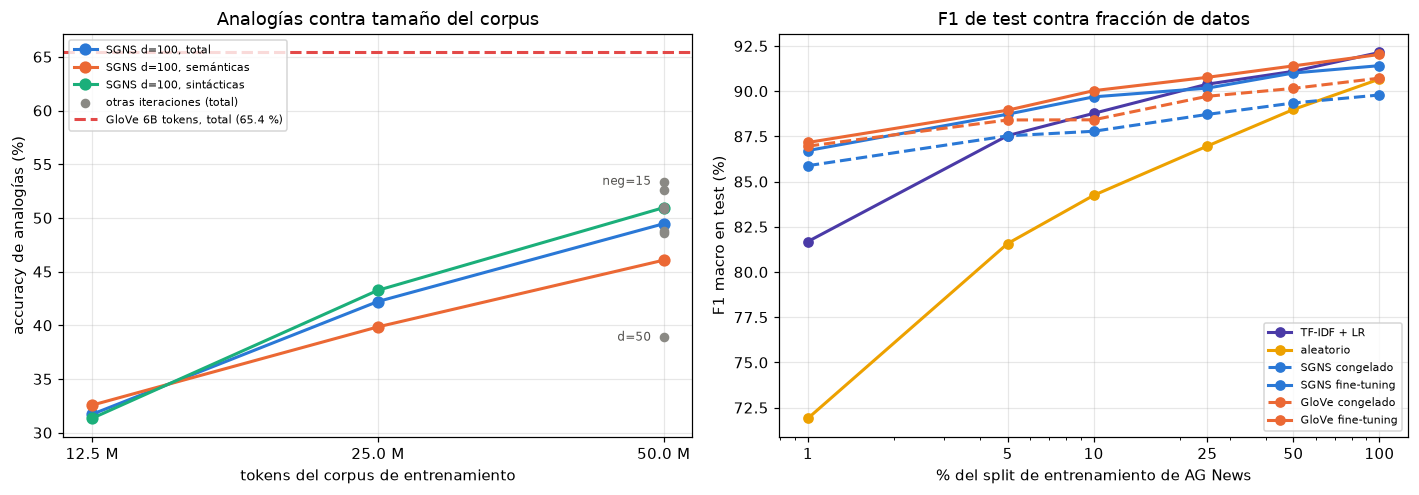

ganancia al duplicar el corpus: 12.5 a 25 M +10.5 puntos | 25 a 50 M +7.2 puntos
mejor cambio de hiperparámetro con 50 M tokens: +3.9 puntos sobre la base
brecha entre el mejor SGNS y GloVe: 12.0 puntos


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# (1) accuracy de analogías contra tokens del corpus
ax = axes[0]
glove_tot = tabla_cat.loc["total", "GloVe 3CosAdd"]
tam = ["it04_corpus25", "it05_corpus50", "it01_base"]
x = np.array([RES[n]["n_tokens"] for n in tam])
for k, (col, etiqueta) in enumerate([("an_total", "total"), ("an_sem", "semánticas"), ("an_sin", "sintácticas")]):
    y = [100 * RES[n]["hist"][-1][col] for n in tam]
    ax.plot(x, y, marker="o", ms=7, lw=2, color=COLORES[k], label=f"SGNS d=100, {etiqueta}")
otras = [n for n in RES if n not in tam]
ax.scatter([RES[n]["n_tokens"] for n in otras], [100 * RES[n]["hist"][-1]["an_total"] for n in otras],
           color="#8a8984", s=28, zorder=3, label="otras iteraciones (total)")
for n, txt in [("it08_neg15", "neg=15"), ("it02_dim50", "d=50")]:
    ax.annotate(txt, (RES[n]["n_tokens"], 100 * RES[n]["hist"][-1]["an_total"]), xytext=(-8, 0),
                textcoords="offset points", ha="right", va="center", fontsize=8, color="#52514e")
ax.axhline(glove_tot, color=COLORES[7], ls="--", lw=2, label=f"GloVe 6B tokens, total ({glove_tot:.1f} %)")
ax.set_xscale("log"); ax.set_xticks(x, [f"{v / 1e6:.1f} M" for v in x]); ax.minorticks_off()
ax.set_xlabel("tokens del corpus de entrenamiento"); ax.set_ylabel("accuracy de analogías (%)")
ax.set_title("Analogías contra tamaño del corpus"); ax.legend(fontsize=7.5, loc="upper left")

# (2) F1 de test contra fracción de datos de AG News
ax = axes[1]
orden = ["TF-IDF + LR", "aleatorio", "SGNS congelado", "SGNS fine-tuning", "GloVe congelado", "GloVe fine-tuning"]
estilos = {"TF-IDF + LR": (COLORES[6], "-"), "aleatorio": (COLORES[3], "-"), "SGNS congelado": (COLORES[0], "--"),
           "SGNS fine-tuning": (COLORES[0], "-"), "GloVe congelado": (COLORES[1], "--"), "GloVe fine-tuning": (COLORES[1], "-")}
for n in orden:
    d = tabla_frac[tabla_frac["modelo"] == n]
    c, ls = estilos[n]
    ax.plot(100 * d["fracción"], 100 * d["f1_test"], marker="o", ms=6, lw=2, color=c, ls=ls, label=n)
ax.set_xscale("log"); ax.set_xticks([1, 5, 10, 25, 50, 100], ["1", "5", "10", "25", "50", "100"])
ax.set_xlabel("% del split de entrenamiento de AG News"); ax.set_ylabel("F1 macro en test (%)")
ax.set_title("F1 de test contra fracción de datos"); ax.legend(fontsize=7.5, loc="lower right")
fig.tight_layout(); fig.savefig("figures/comparacion_corpus_y_fraccion.png", dpi=200); plt.show()

tot = [100 * RES[n]["hist"][-1]["an_total"] for n in tam]
print(f"ganancia al duplicar el corpus: 12.5 a 25 M {tot[1] - tot[0]:+.1f} puntos | 25 a 50 M {tot[2] - tot[1]:+.1f} puntos")
mejor_hp = max(100 * RES[n]["hist"][-1]["an_total"] for n in RES if RES[n]["cfg"]["frac"] == 1.0)
print(f"mejor cambio de hiperparámetro con 50 M tokens: {mejor_hp - tot[2]:+.1f} puntos sobre la base")
print(f"brecha entre el mejor SGNS y GloVe: {glove_tot - tabla_cat.loc['total', 'SGNS 3CosAdd']:.1f} puntos")

## 8. Discusión y análisis

**¿Se cumple la aritmética vectorial en su modelo? ¿En qué categorías de analogías funciona mejor y en cuáles falla? ¿Hay diferencias entre analogías semánticas y sintácticas?**

Se cumple en parte: el mejor SGNS acierta 53.4 % de las 12,181 preguntas con 3CosAdd y 14 de las 19 analogías propias. Funciona mejor en nacionalidad-adjetivo (87.1 %), tiempo pasado (72.1 %) y capitales comunes (68.8 %), y falla en monedas (0 %), opuestos (15.8 %) y adjetivo-adverbio (18.8 %). Las sintácticas (54.2 %) superan a las semánticas (51.5 %), porque estas dependen de entidades que aparecen poco en 50 millones de tokens, como monedas y capitales de países pequeños. 3CosMul quedó por debajo de 3CosAdd en los tres modelos.

**¿Es el "aproximadamente igual" de king - man + woman = queen una igualdad?**

No. Sin excluir la consulta, la palabra más cercana a b - a + c es c en 85.6 % de las preguntas (king para king - man + woman) y la respuesta correcta solo en 9.2 %. El coseno entre queen y el vector resultante es 0.74. Los vectores diferencia de una relación tienen coseno medio de 0.25 en SGNS y 0.40 en GloVe, contra 0 para pares al azar: comparten una dirección pero no son paralelos. La analogía acierta porque la respuesta es la más cercana después de excluir a, b y c, y las categorías con más paralelismo tienen más accuracy (Spearman de 0.51 en SGNS y 0.90 en GloVe).

**¿Qué tan lejos quedó su modelo de GloVe? ¿Cuánto de la diferencia se explica por el tamaño del corpus y cuánto por el método o los hiperparámetros?**

Quedó 12 puntos abajo en analogías (53.4 % contra 65.4 %) y arriba en WordSim-353 (0.673 contra 0.533). Duplicar el corpus de 12.5 a 25 millones de tokens sumó 10.5 puntos y de 25 a 50 millones 7.2, mientras que el mejor cambio de hiperparámetros sumó 3.9. GloVe usó 120 veces más tokens, unas 7 duplicaciones; con 2 puntos por duplicación se cubriría la brecha, así que la mayor parte se explica por el corpus. El método pesa en el tipo de relación: GloVe gana en capitales del mundo (86.3 % contra 62.3 %) y familia (88.0 % contra 57.9 %), y SGNS en ciudad-estado (40.1 % contra 29.8 %), tiempo pasado (72.1 % contra 58.8 %) y similitud.

**¿Su implementación de SGNS se comporta parecido a la de gensim? Si hay diferencias, ¿a qué se deben?**

Sí. Con el mismo corpus, vocabulario (144,751 palabras) e hiperparámetros, SGNS llega a 53.4 % en analogías y gensim a 51.3 %; quedan igual en sintácticas (54.2 % y 54.1 %) y en WordSim-353 (0.673 y 0.675), con tiempos de 3.8 min en GPU y 4.8 min en CPU. La diferencia está en las semánticas (51.5 % contra 44.9 %) y viene del optimizador: SparseAdam normaliza el paso de cada parámetro y una palabra rara recibe actualizaciones del mismo tamaño que una frecuente, mientras que el SGD de gensim la deja cerca de su inicialización. Por eso los vecinos de "king" en gensim son nombres raros ("harthacnut", "chlothar") y en SGNS son "queen", "throne" y "prince". gensim queda arriba en SimLex-999 (0.314 contra 0.280).

**¿Qué efecto tuvieron la dimensión del embedding, el tamaño de ventana y el número de negativos? ¿Las ventanas pequeñas favorecen relaciones sintácticas o semánticas?**

Con d=50 el total bajó de 49.5 % a 38.9 %; con d=300 subió a 52.6 %, pero WordSim bajó de 0.674 a 0.637 y cada epoch tardó casi 6 veces más. Con 15 negativos se obtuvo el mejor resultado (53.4 %) al doble de tiempo. La ventana 2 subió las sintácticas a 55.4 % y bajó las semánticas a 41.0 %; la ventana 10 dio 46.4 % y 49.6 %. Las ventanas pequeñas favorecen las relaciones sintácticas, porque los vecinos inmediatos reflejan la función gramatical; las grandes capturan el tema.

**En AG News, ¿los embeddings preentrenados superaron a los aleatorios y al baseline TF-IDF? ¿Cuándo convino congelar y cuándo hacer fine-tuning? ¿Cómo cambia la respuesta con 1 % de los datos?**

Con todos los datos, GloVe (92.0 % de F1 en test) y SGNS (91.4 %) con fine-tuning superaron a los aleatorios (90.7 %), pero no a TF-IDF (92.1 %), que usa bigramas y 424 mil rasgos. Fine-tuning superó a congelar en todas las fracciones, porque congelado solo se entrenan los 26,884 parámetros del MLP y los vectores no se adaptan a las noticias. Con 1 % de los datos (1,080 noticias) los preentrenados quedan entre 85.9 % y 87.2 %, contra 71.9 % de los aleatorios y 81.7 % de TF-IDF, y congelar queda a menos de un punto de fine-tuning con 185 veces menos parámetros entrenables. Congelar conviene con pocos datos y el fine-tuning con decenas de miles de ejemplos.

## Conclusiones

1. El SGNS propio en PyTorch alcanzó 53.4 % en analogías, 2.1 puntos más que gensim con el mismo corpus y vocabulario.
2. El tamaño del corpus pesó más que los hiperparámetros: duplicar los tokens sumó entre 7.2 y 10.5 puntos y el mejor cambio de hiperparámetro sumó 3.9.
3. GloVe superó al mejor SGNS por 12 puntos en analogías, pero quedó por debajo en WordSim-353.
4. La aritmética vectorial es aproximada: sin excluir la consulta, la palabra c fue la más cercana en 85.6 % de las preguntas.
5. Con 1 % de AG News, los embeddings preentrenados superaron a los aleatorios por 14 a 15 puntos de F1.